# <center>🤖 Лекция 1. Что такое искусственный интеллект</center>
## <center>人工智能是什么</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 1 — Основы ИИ и подготовка инструментальной среды · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснить своими словами, что такое искусственный интеллект (人工智能) и чем он отличается от обычной программы;<br>2. разобрать на примерах, как «обучение на данных» отличается от «правил, написанных человеком»;<br>3. назвать основные направления ИИ и привести по примеру из жизни для каждого;<br>4. рассказать о 7–9 ключевых событиях истории ИИ и объяснить, почему бум случился именно сейчас;<br>5. назвать профессии индустрии ИИ и их инструменты;<br>6. понимать ограничения современных систем: узкий ИИ, галлюцинации, ответственность.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• ИИ вокруг нас: утро студента <i>(15 мин)</i><br>• Что такое ИИ: определение, тест Тьюринга, узкий vs общий <i>(20 мин)</i><br>• Программа vs обучающаяся модель: аналогия со спамом <i>(25 мин)</i><br>• История ИИ: 1950 → 2025 и три причины бума <i>(15 мин)</i><br>• Направления ИИ и профессии <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> Jupyter Notebook, среда ai_course из Практики 1.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


> **Как работать с ноутбуком.** Теория читается сверху вниз; все рисунки внедрены в файл — внешние картинки не нужны. Ячейки с кодом можно запускать в любом порядке после первой настроечной ячейки. Вопросы в рамках **❓** — для обсуждения на паре или в парах.

## 1. ИИ вокруг нас: утро обычного студента

**❓ Вопрос к аудитории:** *«Сколько раз сегодня вы воспользовались искусственным интеллектом, даже не заметив этого?»*

Обычно называют два-три приложения. Реальная цифра для студента в кампусе — **несколько десятков**. Разберём один день по часам:


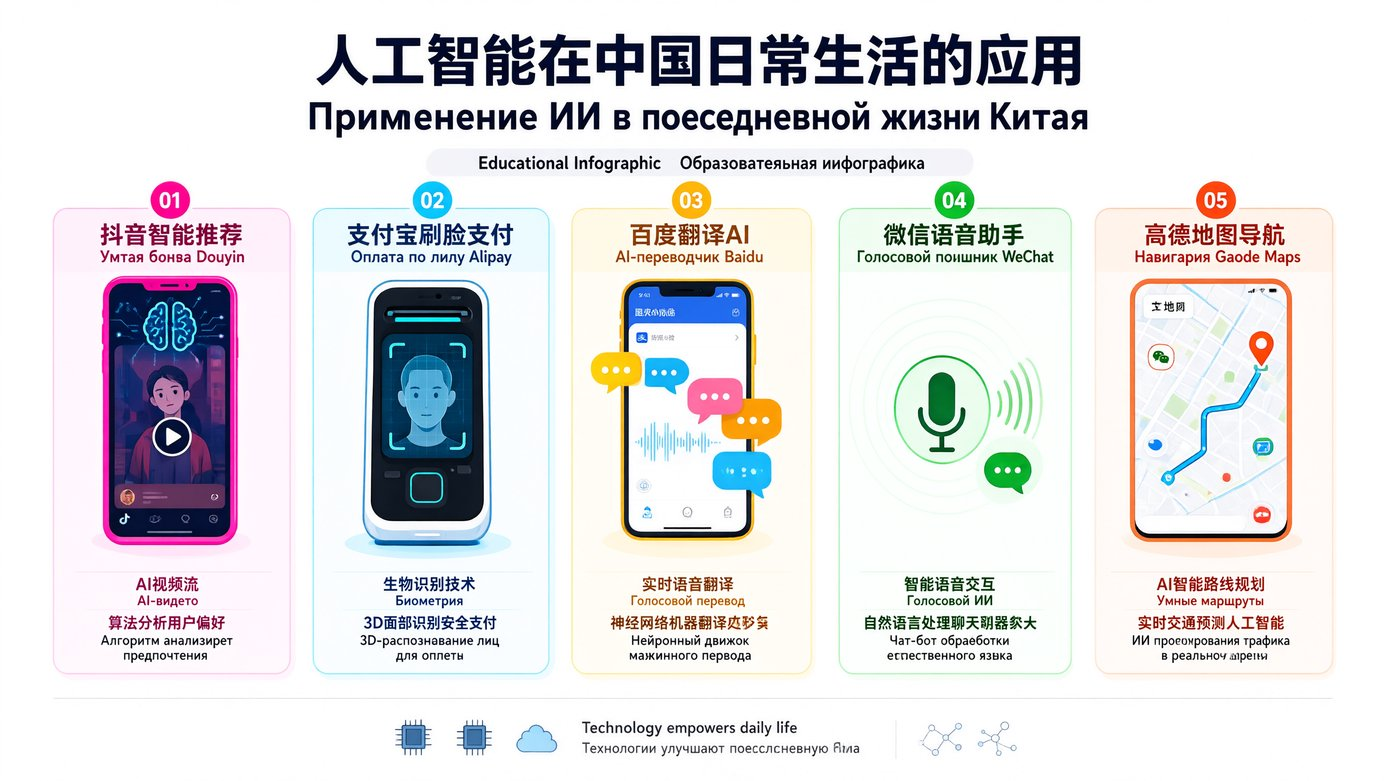

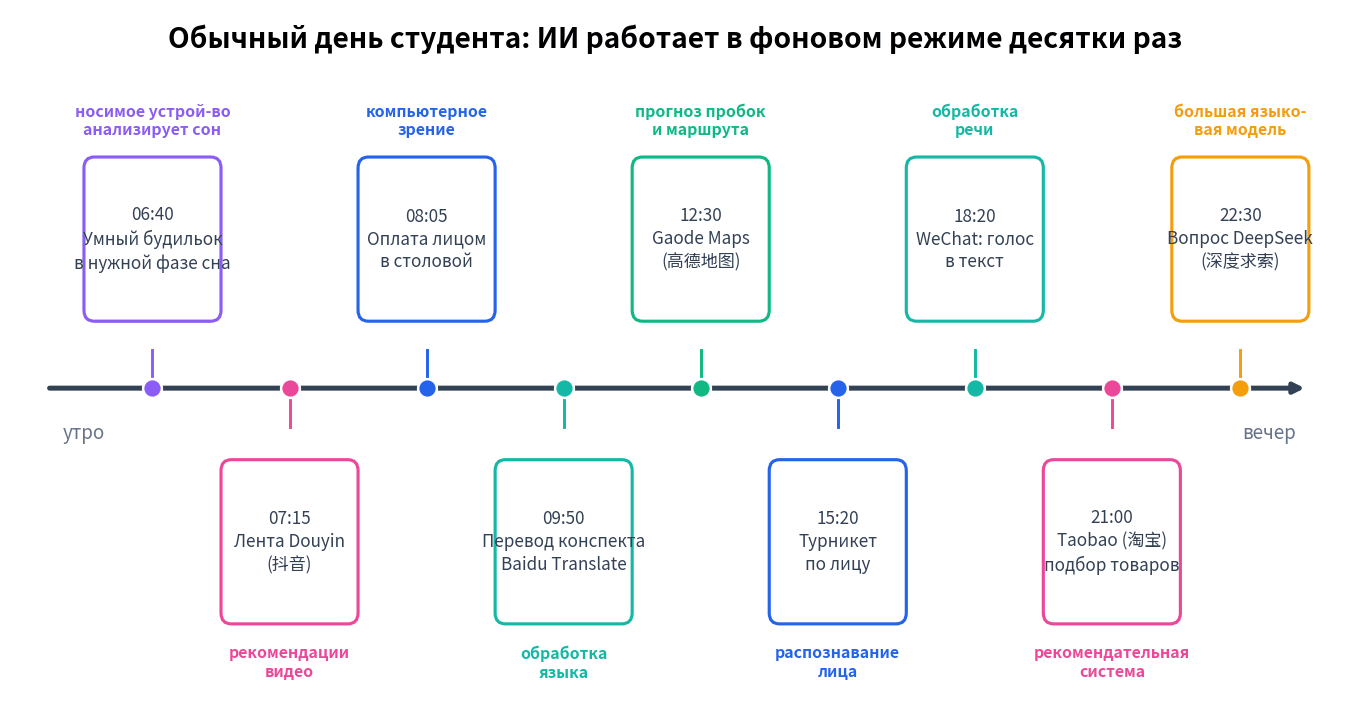

Обратите внимание: ИИ почти всегда **невидим** — он спрятан внутри привычных действий: открыть ленту, приложить лицо к терминалу, спросить дорогу. Пользователь видит только результат — «удобно».

### 1.1. Таблица применений: что именно делает ИИ

| Ситуация | Что делает ИИ внутри | Направление |
|---|---|---|
| **Douyin (抖音)** показывает видео, которые вам нравятся | предсказывает интересы по истории просмотров | машинное обучение (рекомендации) |
| **Оплата лицом** в Alipay (支付宝) и WeChat Pay | сравнивает лицо с сохранённым образцом | компьютерное зрение |
| **Baidu Translate (百度翻译)**, Youdao (有道) | переводит текст между языками | обработка естественного языка |
| **Xiao AI (小爱同学)**, Xiaodu (小度) | превращает речь в текст и обратно | обработка речи |
| **Gaode Maps (高德地图)**, Baidu Maps | прогнозирует пробки и время в пути | машинное обучение |
| **Taobao (淘宝)** подбирает товары | предсказывает вероятность покупки | рекомендации |
| **DeepSeek (深度求索)**, Qwen (通义千问), Kimi | пишет тексты, отвечает на вопросы, помогает с кодом | большие языковые модели |

**Закономерность во всей таблице одна:** на входе — данные о прошлом (ваши просмотры, покупки, маршруты), внутри — поиск закономерностей, на выходе — предсказание или решение.

### 1.2. Разбор примеров «под микроскопом»

#### Douyin: как приложение угадывает вкусы

1. Приложение записывает **сигналы**: что вы досмотрели до конца, что пролистали за секунду, что лайкнули, что переслали, сколько смотрели автора ранее.
2. Сигналы превращаются в **числа** — признаки (features, 特征): `досмотрел = 1`, `лайкнул = 1`, `пролистал = 0`…
3. «Правильный ответ» для каждого видео известен из вашего поведения: понравилось или нет.
4. Модель ищет закономерности: *пользователи с похожей историей просмотров чаще досматривают такие-то видео*.
5. Для нового видео модель оценивает вероятность «понравится» и лента сортируется по этой вероятности.

#### Оплата лицом: как это работает

Камера снимает лицо → программа находит лицо на кадре (даже под углом, в очках) → превращает его в **вектор из ~128 чисел** (геометрия: расстояния между глазами, форма скул, пропорции) → сравнивает с вектором, сохранённым при регистрации → если векторы «близки» (расстояние меньше порога) — платёж подтверждается. Заметьте: система не «узнаёт вас как человека» — она сравнивает **числовые отпечатки**.

#### Навигация Gaode: прогноз пробок

Телефоны миллионов пользователей (пусть и анонимно) сообщают скорость движения → алгоритм видит, где замедление → предсказывает, как пробка будет расти и рассасываться → строит быстрый маршрут с учётом **будущего**, а не только настоящего.


#### 🌐 Перевод в Baidu Translate (создание текста)

Модель обучена на огромном числе пар предложений на двух языках. Для нового предложения она выбирает наиболее вероятный перевод. Поэтому обычные фразы переводятся хорошо, а идиомы и чэнъюй (成语) часто теряют смысл. Попросите студентов перевести одну китайскую пословицу и обсудить результат.

---

### ✏️ Упражнение «Найди ИИ» (5 минут, в парах)

Назовите **три приложения** на вашем телефоне, где, по-вашему, работает ИИ. Что именно он угадывает или распознаёт? Выслушайте 3–4 пары.

Для самопроверки: отнесите каждый пример к одному из трёх типов (**распознаёт**, **прогнозирует**, **создаёт**) и назовите, какие данные ему нужны.

> 💡 **Вывод:** почти всегда ИИ либо **распознаёт** (лицо, речь, текст), либо **прогнозирует** (что вам понравится, сколько ехать), либо **создаёт** (текст, картинку).

> **Мораль параграфа:** «магии нет». На входе данные, внутри поиск закономерностей, на выходе ответ. Всё остальное — масштаб.


## 2. Что такое искусственный интеллект

Когда говорят об анализе данных, часто используют разные термины: аналитика данных, экспертные системы, машинное обучение, глубокое обучение, Data Science. На первый взгляд кажется, что это совершенно разные области, но на самом деле все они относятся к большой сфере искусственного интеллекта (Artificial Intelligence, AI).

**Искусственный интеллект (人工智能)** — это область компьютерных наук, где создаются программы, решающие задачи, для которых обычно нужен человеческий интеллект: распознавание, понимание речи и текста, принятие решений.  В отличие от классической аналитики, где специалист вручную задает правила и формулы, модели машинного обучения учатся на примерах и сами выявляют зависимости.

---


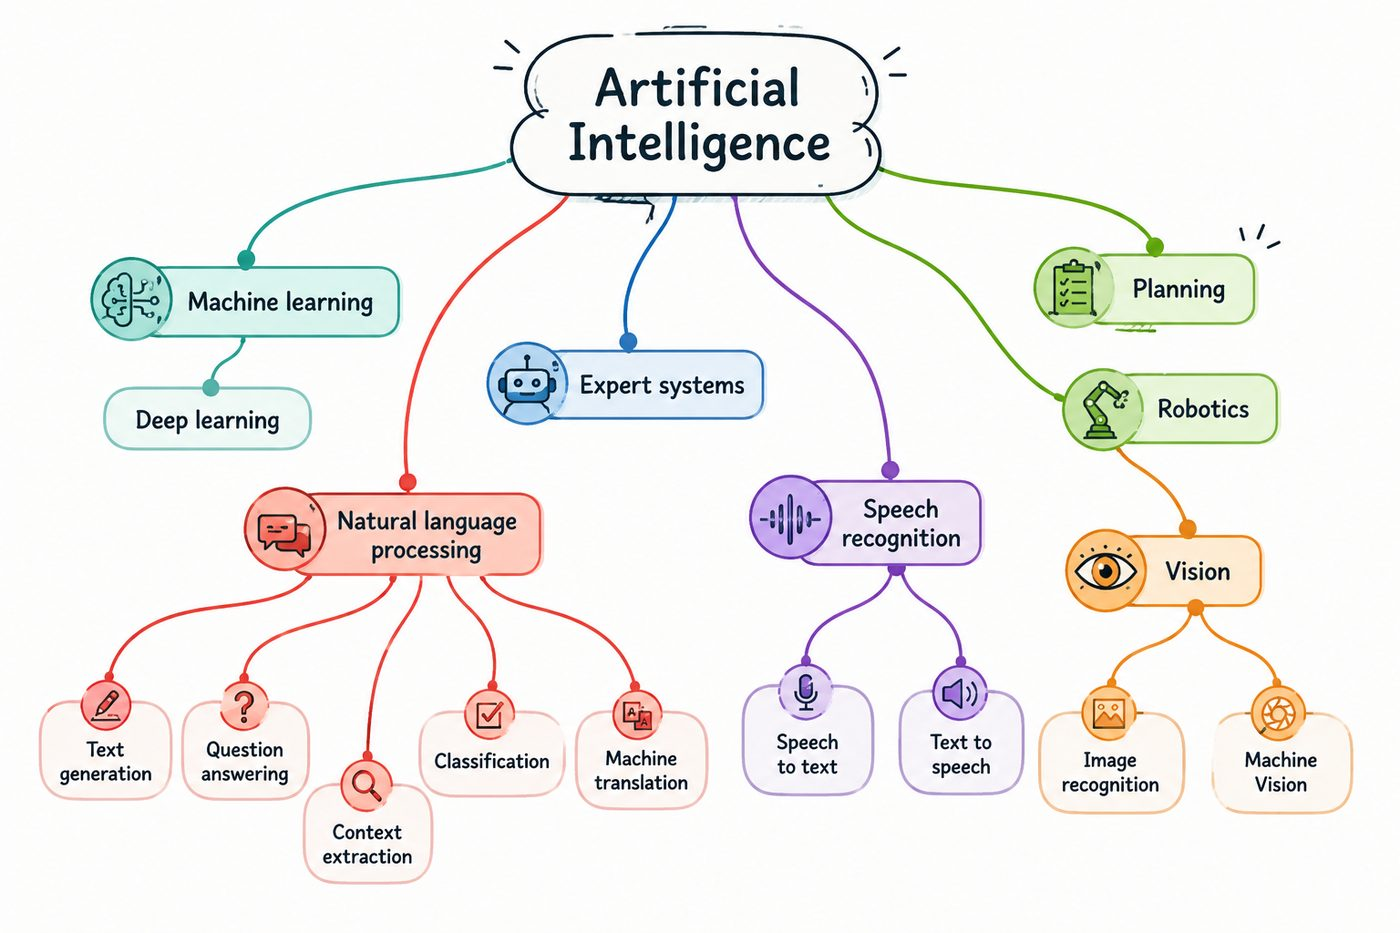

### 2.1. Три определения — от строгого к рабочему

**Историческое (Алан Тьюринг, 1950).** Тьюринг предложил не определять «мышление», а проверить его имитацию — «имитационную игру», которую сегодня называют **тестом Тьюринга**:


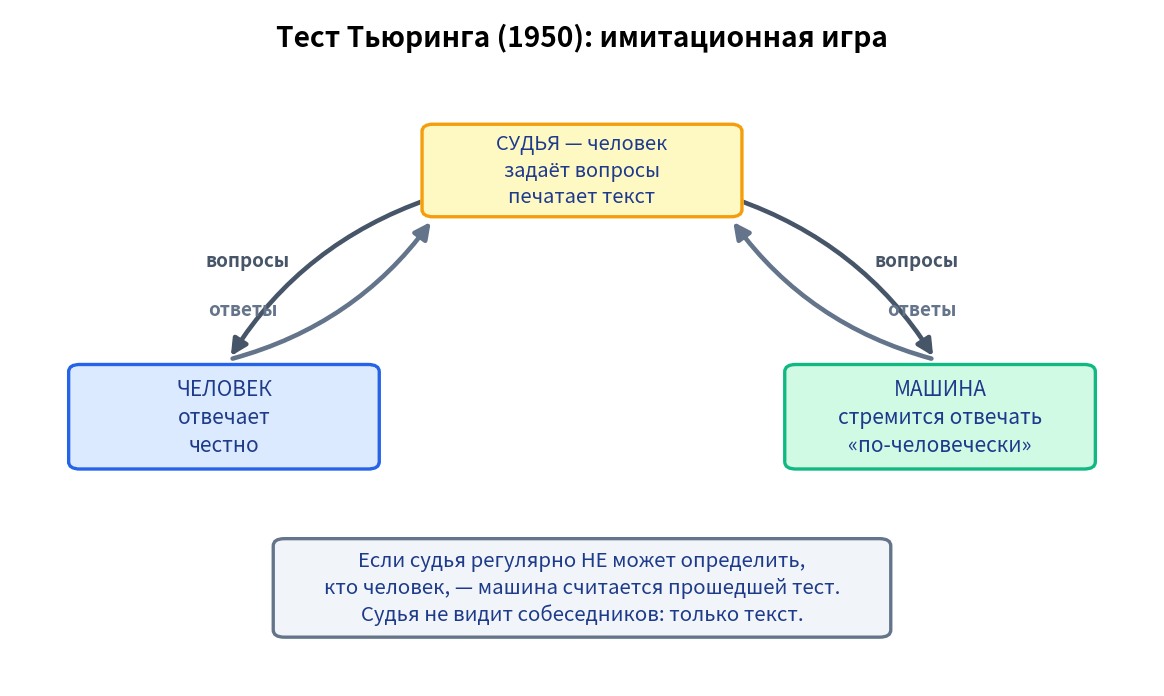
Судья переписывается текстом с двумя невидимыми собеседниками — человеком и машиной. Если судья регулярно не может определить, кто есть кто, машина считается прошедшей тест. Важная тонкость: тест проверяет **умение вести осмысленный диалог**, а не «понимание» в человеческом смысле.

**Учредительное (Дартмут, 1956).** Джон Маккарти предложил термин на легендарном летнем семинаре: *«наука и инженерия создания интеллектуальных машин»*. Никакой мистики: ИИ — раздел инженерии.

**Рабочее (как будем понимать мы).**

> **Искусственный интеллект** — это широкий класс систем, которые выполняют задачи, традиционно требующие человеческого интеллекта (восприятие, понимание языка, решение задач, планирование), причём система **самостоятельно улучшается на основе данных**.

Слова «самостоятельно улучшается на данных» — ключевые: они отделяют обучающиеся системы от «просто умных программ».

### 2.2. Узкий ИИ и AGI: важнейшее различие курса


### 🔬 Узкий ИИ и «общий» ИИ

Всё, что существует сегодня, — **узкий ИИ (弱人工智能)**: он хорошо делает одну задачу (играет в го, переводит, узнаёт лица), но не «понимает мир», как человек. Идея **общего ИИ (通用人工智能)**, способного решать любые задачи на уровне человека, пока остаётся целью исследований и предметом споров.


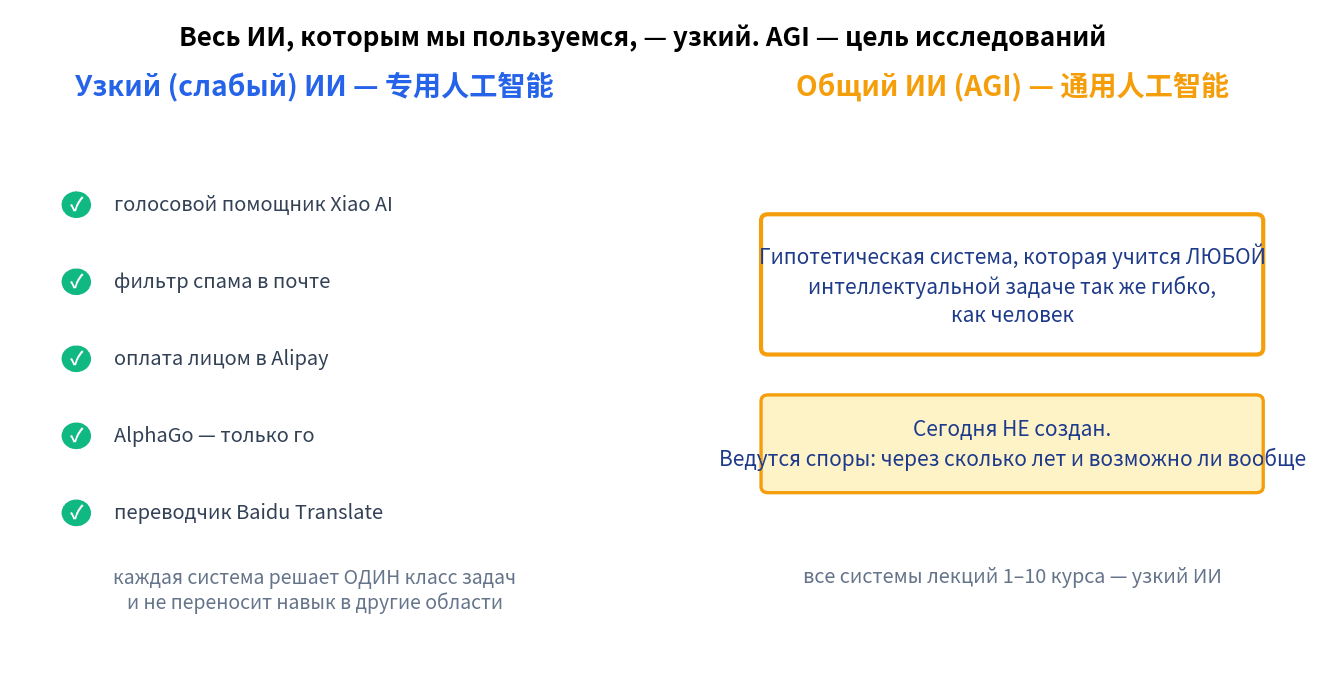

**Узкий ИИ (narrow AI, 专用人工智能)** — система, решающая один класс задач: фильтр спама не играет в го, а AlphaGo не пишет письма. **Абсолютное всё**, чем вы пользуетесь сегодня, включая ChatGPT и DeepSeek, — узкий ИИ (очень широкий, но узкий).

**Общий ИИ (AGI, 通用人工智能)** — гипотетическая система, которая переносит навыки между областями так же гибко, как человек. Не создан. Сроки и сама возможность — предмет открытых научных споров. В этом курсе мы честно говорим: строим и изучаем узкий ИИ.

### 2.3. Вложенность понятий: ИИ ⊃ МО ⊃ ГО

Три термина постоянно путают. Правильная картинка — **матрёшка**:


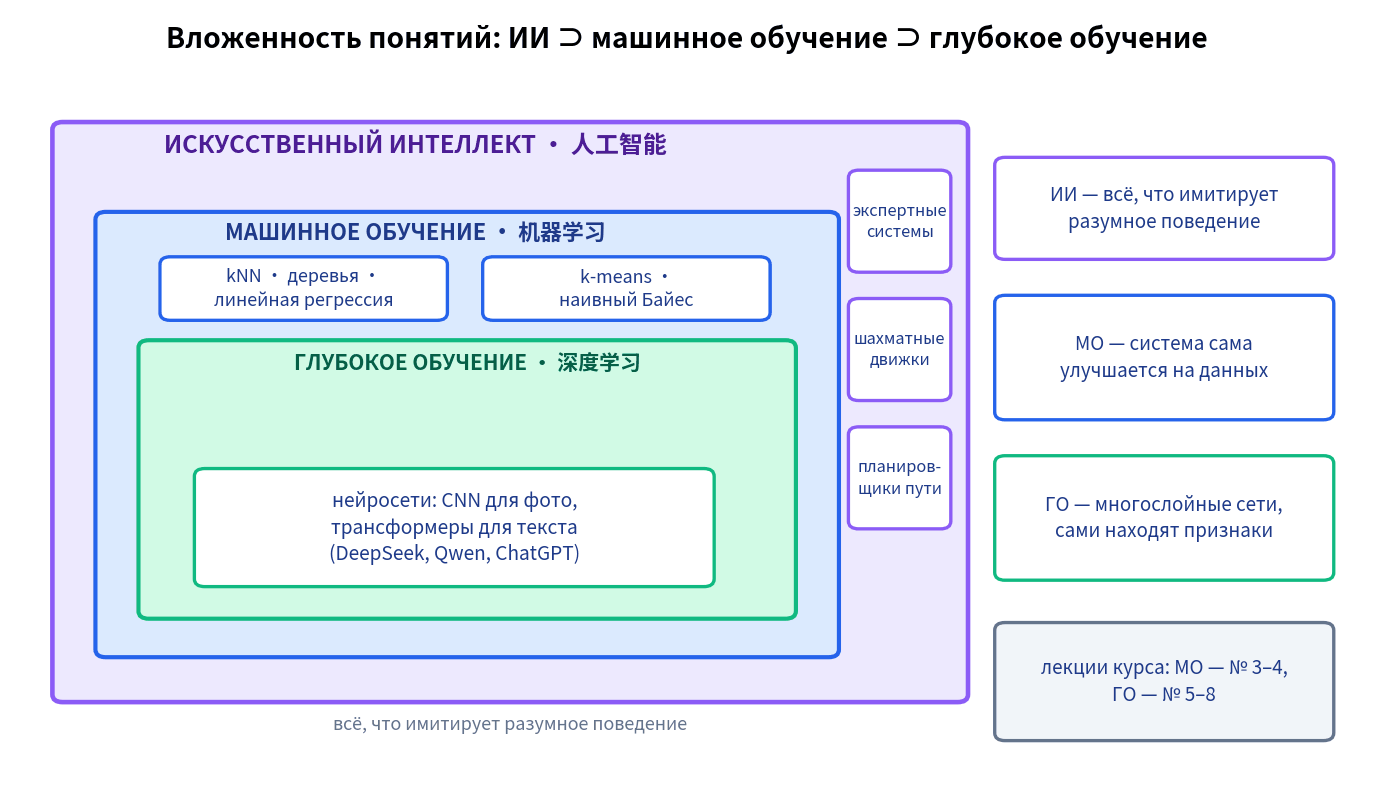
- **Искусственный интеллект** — всё, что имитирует разумное поведение: экспертные системы 1970-х, шахматные движки, планировщики. Могут работать по жёстким правилам без обучения.
- **Машинное обучение** — часть ИИ, где система **сама улучшается на данных**: kNN, деревья решений, линейная регрессия, k-means (лекции 3–4).
- **Глубокое обучение** — часть МО, где используются **многослойные нейросети**, которые сами находят признаки в сырых данных: CNN для фото, трансформеры для текста (лекции 5–8).

**❓ Вопрос на закрепление:** «Шахматный движок, который обыгрывает гроссмейстера, но не может объяснить ни одного своего хода — это ИИ, МО или ГО?» *(Ответ: ИИ. Современные сильнейшие движки вроде AlphaZero — уже ГО; классические типа Stockfish-классики — ИИ без обучения.)*



### 🤖 ИИ — это не робот: «мозг» и «тело»

Полезное уточнение, которое снимает частую путаницу. **Робот** — физическое тело с моторами и датчиками; **ИИ** — «мозг», программа, которая принимает решения. Робот-пылесос без алгоритма навигации просто тыкается в стены; а алгоритм планирования пути без всякого робота полезен — тот же алгоритм работает в навигаторе 高德地图. **В курсе мы изучаем именно «мозг»: наш ИИ живёт в ноутбуке и не требует железа.**


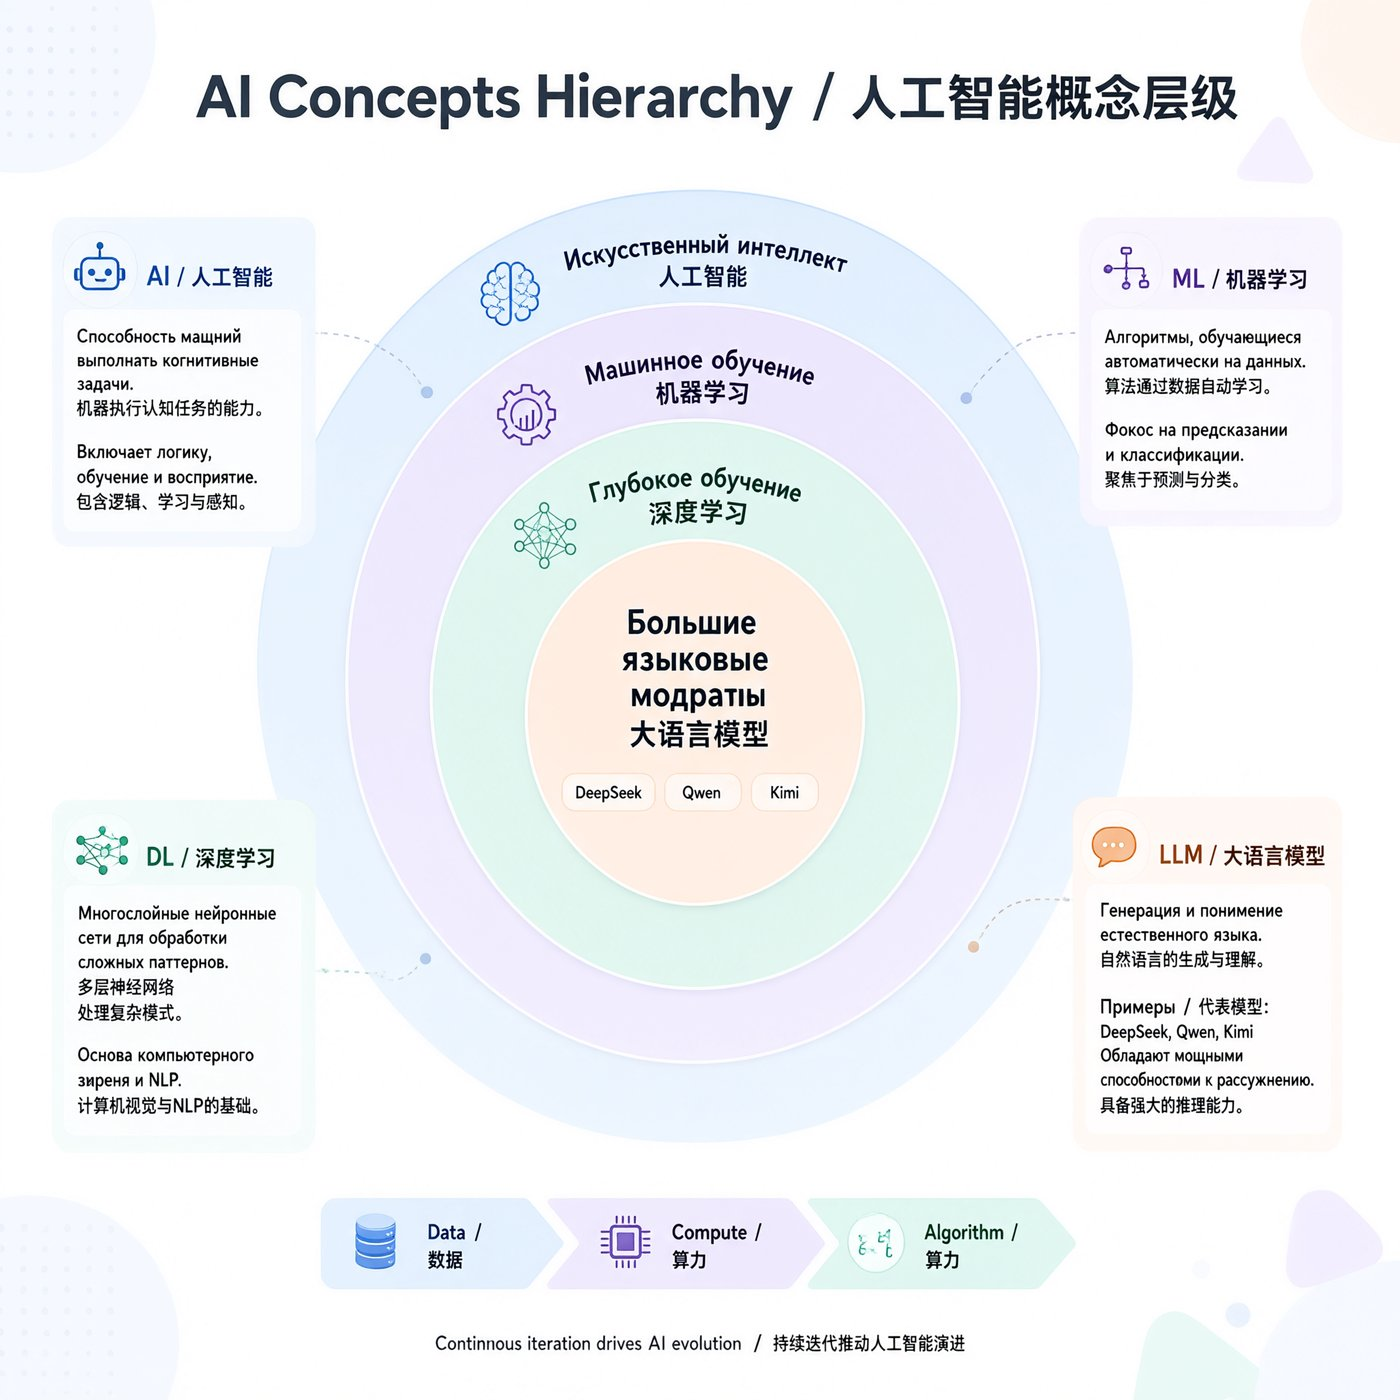

**Машинное обучение (Machine Learning)** находится на стыке сразу нескольких областей: математики, программирования и прикладных дисциплин. Например, чтобы создать систему диагностики заболеваний по МРТ-снимкам или модель для оценки кредитоспособности клиентов, нужны не только алгоритмы машинного обучения, но и понимание специфики данных.

При этом специалисту по Data Science необязательно быть экспертом во всех предметных областях. Его задача — подготовить данные, выбрать модель, обучить ее и оценить качество, а интерпретацией результатов и их применением обычно занимаются профильные специалисты.

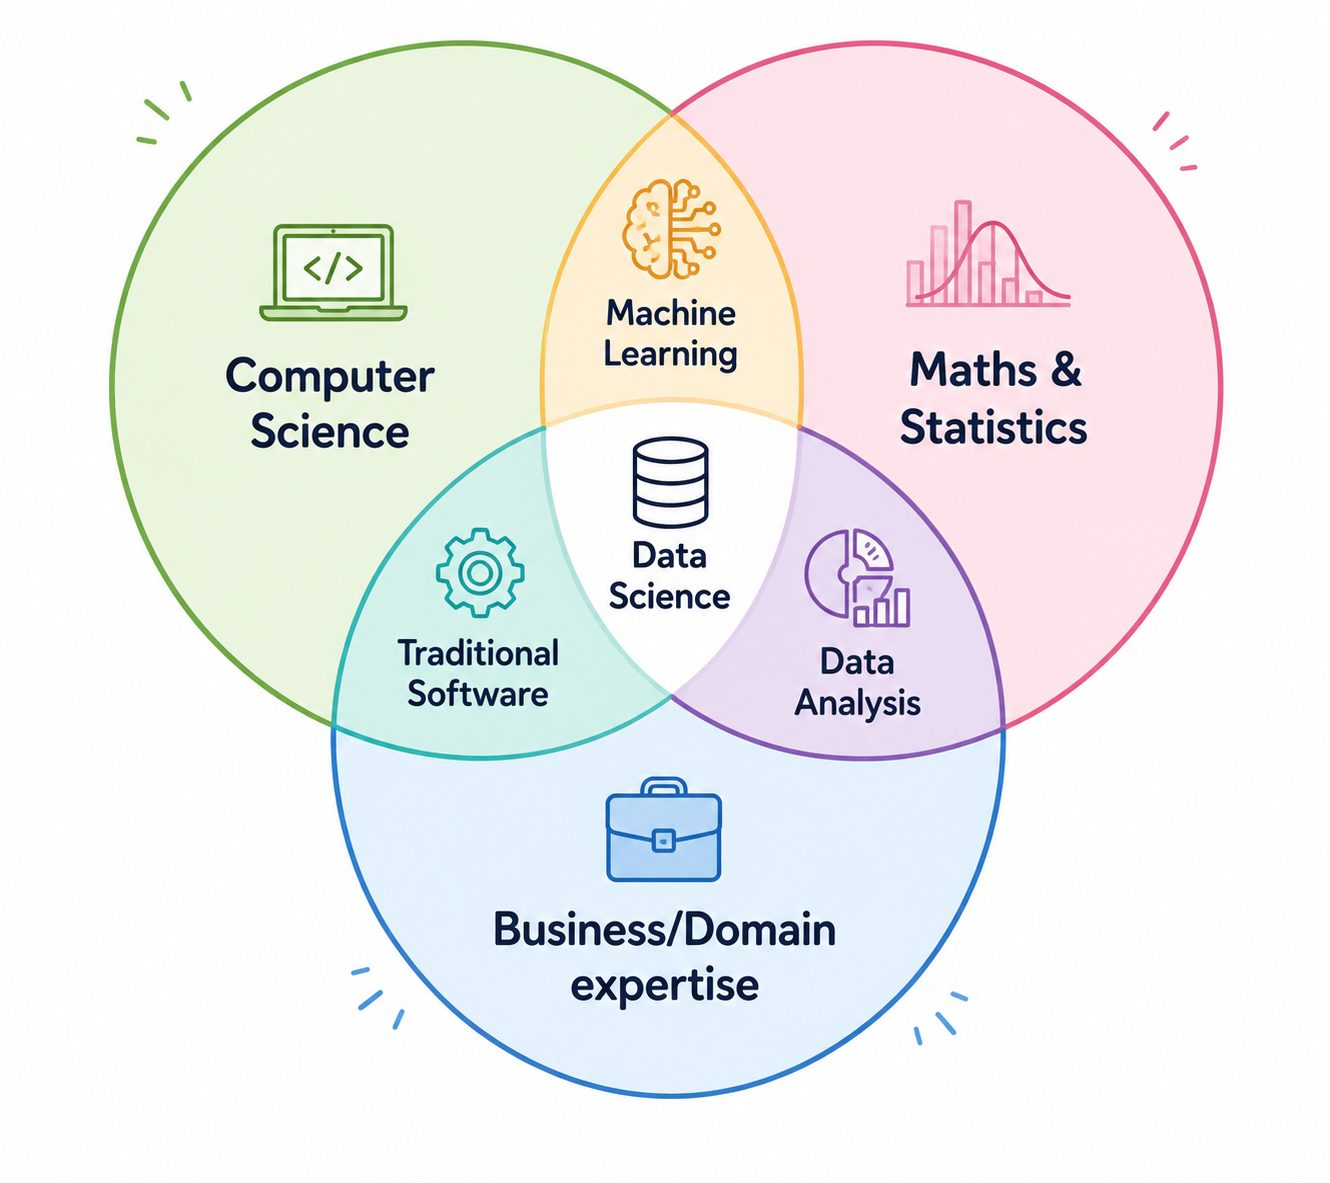

Конечно, знания предметной области помогают создавать более качественные модели и лучше понимать результаты. Но самое важное для исследователя данных — хорошо знать математику, понимать принципы работы алгоритмов и уметь писать качественный код. Именно эти навыки позволяют создавать надежные модели, способные решать реальные задачи.

**Глубокое обучение (Deep Learning)** — это одно из самых быстроразвивающихся направлений машинного обучения. Его основная особенность заключается в использовании искусственных нейронных сетей, состоящих из большого количества слоев. Благодаря такой архитектуре модели способны самостоятельно извлекать сложные закономерности из данных, практически не требуя ручного создания признаков.

Именно глубинное обучение стало основой большинства современных достижений в области искусственного интеллекта. Сегодня нейронные сети распознают изображения и речь, переводят тексты, управляют беспилотными автомобилями, генерируют изображения, музыку и видео, а также лежат в основе больших языковых моделей, таких как ChatGPT.

По сравнению с классическими алгоритмами машинного обучения нейронные сети обычно требуют значительно большего объема данных и вычислительных ресурсов. Однако именно они позволяют решать задачи, которые еще несколько лет назад считались практически невыполнимыми.



В этом курсе мы начнем с классических методов машинного обучения, чтобы понять фундаментальные принципы анализа данных. А затем познакомимся с основами глубинного обучения и увидим, как нейронные сети позволяют решать задачи компьютерного зрения, обработки естественного языка и других современных направлений искусственного интеллекта.

Какие знания нужны для изучения ИИ?
Искусственный интеллект объединяет несколько областей знаний, поэтому хорошему специалисту важно развивать сразу несколько навыков.

Математика. Линейная алгебра, математический анализ, теория вероятностей и математическая статистика лежат в основе большинства алгоритмов машинного обучения.
Программирование. Необходимо уметь писать код, работать с данными и использовать современные библиотеки для анализа данных и обучения моделей. Сегодня основным языком для машинного обучения является Python.
Алгоритмы и структуры данных. Понимание принципов работы алгоритмов помогает создавать эффективные и масштабируемые решения.
Предметная область. Знание бизнеса, медицины, финансов или другой сферы не является обязательным, но позволяет лучше понимать данные и создавать более качественные модели.
Главное — не пытаться освоить все сразу. Большинство специалистов начинают с математики, Python и классического машинного обучения, а затем постепенно переходят к более сложным темам, таким как глубокое обучение, большие языковые модели и AI-агенты.

## 3. Обычная программа против обучающейся модели

### 3.1. Аналогия с кухней

**Обычная программа — это рецепт.** Повар (программист) заранее расписал каждый шаг: «взять 2 яйца, жарить 4 минуты». Рецепт не меняется от того, удались ли блины.

**Модель ИИ — это повар, выросший на дегустациях.** Он попробовал сотни блинов (данные) с оценками «лучше/хуже» (метки) и сам вывел, что масло в тесте улучшает результат. Повар не писал рецепт заранее — **рецепт («правила») получен из опыта**.

### 3.2. Схема: куда двигается «интеллект»


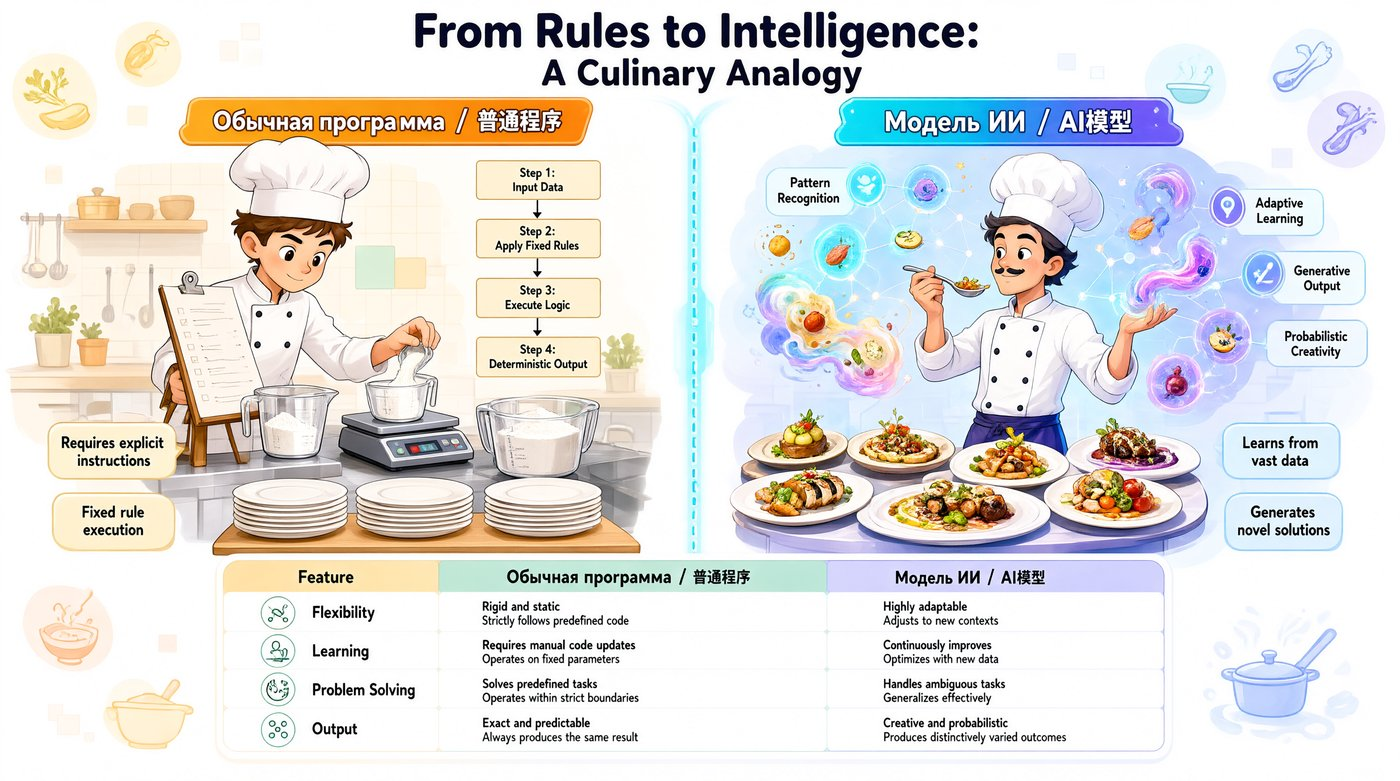

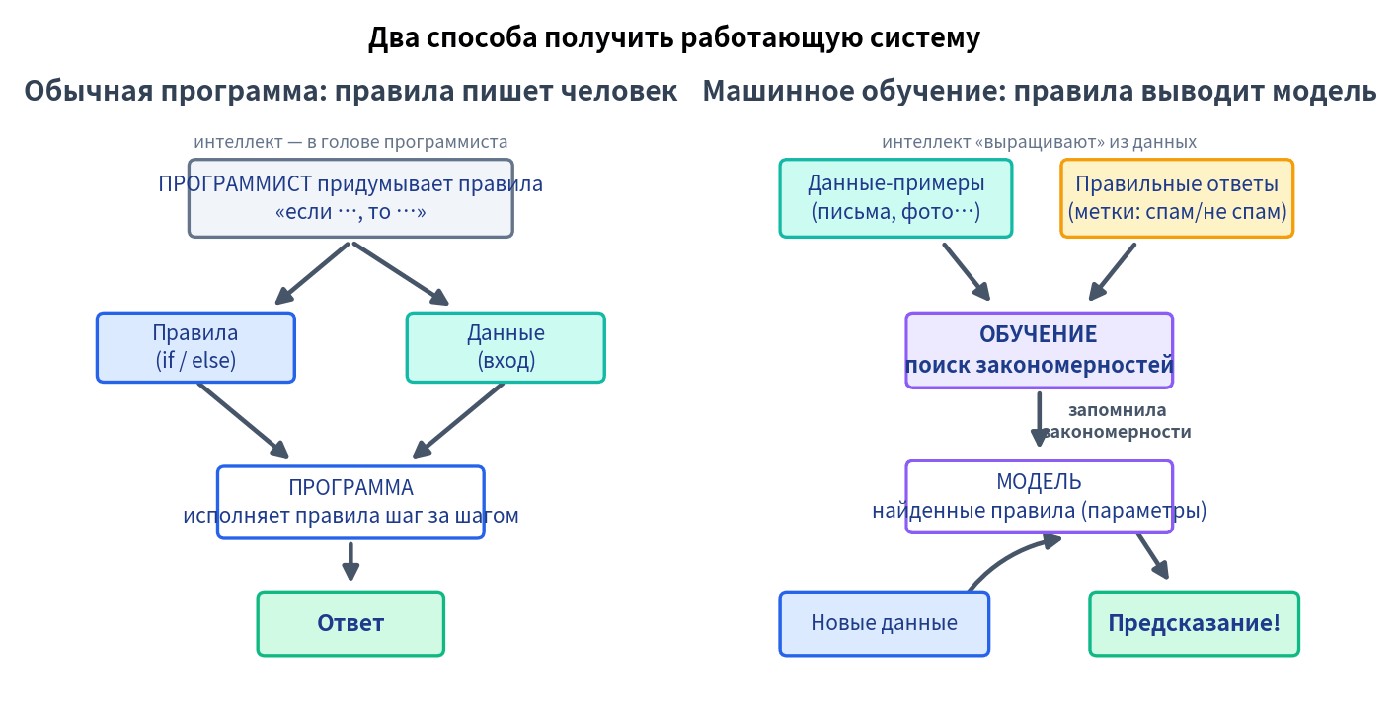

Слева интеллект живёт **в голове программиста**: он придумал правила, программа лишь исполняет. Справа интеллект **выращивается из данных**: человек показывает примеры с ответами, а алгоритм поиска закономерностей находит правила сам.

Формула для запоминания:

$$\text{Классическое программирование: } \text{правила} + \text{данные} \Rightarrow \text{ответы}$$
$$\text{Машинное обучение: } \text{данные} + \text{ответы} \Rightarrow \text{правила (модель)}$$

### 3.3. Полный разбор: фильтр спама

Представьте почтовый сервис. Команда из 1990-х писала бы правила вручную:


In [ ]:
# Подход 1: правила пишет человек (так работали фильтры 1990-х)
def is_spam_rules(text):
    if 'выиграли' in text:      return True
    if 'приз' in text:          return True
    if 'кликните' in text:      return True
    if 'расписание' in text:    return False
    return False

письма = ["Вы выиграли миллион!", "Отчёт по лабе, смотри файл",
          "Заберите ваш приз сегодня", "Расписание пар на понедельник"]
for п in письма:
    print(f"{п!r:45s} -> спам? {is_spam_rules(п)}")

'Вы выиграли миллион!'                        -> спам? True
'Отчёт по лабе, смотри файл'                  -> спам? False
'Заберите ваш приз сегодня'                   -> спам? True
'Расписание пар на понедельник'               -> спам? False


In [ ]:
# Подход 2: "обучение" — система сама считает опасность слов по примерам
учебные = [("Вы выиграли миллион", True), ("Скидка 90% только сегодня", True),
           ("Отчёт по лабе, смотри файл", False), ("Расписание пар", False),
           ("Кликни и получи приз", True), ("Собрание группы в 18:00", False)]

вес = {}                                   # вес слова: положительный = подозрительный
for текст, спам in учебные:
    for слово in текст.lower().split():
        вес[слово] = вес.get(слово, 0) + (1 if спам else -1)

def is_spam_learned(text, порог=0):
    счёт = sum(вес.get(сл, 0) for сл in text.lower().split())
    return счёт > порог, счёт

print("Выученные веса слов:", {k: v for k, v in sorted(вес.items(), key=lambda x: -x[1]) if v != 0})
for п in письма:
    спам, счёт = is_spam_learned(п)
    print(f"{п!r:45s} -> спам? {спам}  (счёт={счёт:+d})")

Выученные веса слов: {'вы': 1, 'выиграли': 1, 'миллион': 1, 'скидка': 1, '90%': 1, 'только': 1, 'сегодня': 1, 'кликни': 1, 'и': 1, 'получи': 1, 'приз': 1, 'отчёт': -1, 'по': -1, 'лабе,': -1, 'смотри': -1, 'файл': -1, 'расписание': -1, 'пар': -1, 'собрание': -1, 'группы': -1, 'в': -1, '18:00': -1}
'Вы выиграли миллион!'                        -> спам? True  (счёт=+2)
'Отчёт по лабе, смотри файл'                  -> спам? False  (счёт=-5)
'Заберите ваш приз сегодня'                   -> спам? True  (счёт=+2)
'Расписание пар на понедельник'               -> спам? False  (счёт=-2)


**Что произошло во второй ячейке?** Мы не писали правила «если слово X — спам». Мы показали 6 примеров с ответами, и **веса слов вычислились сами** из данных. Настоящие фильтры устроены так же, только примеров миллионы и формула весов строже (её мы выведем в лекции 3–4: наивный байесовский классификатор).

Проверьте: письмо «Поздравляем, вы выиграли приз — заберите сегодня» — оба подхода скажут «спам». А письмо «Вы выиграли квоту на общежитие» (шаблон деканата)? Правила скажут «спам» (слово «выиграли»), а обученный фильтр, видевший много писем деканата, скажет «не спам». **Обучающиеся системы гибче именно поэтому.**


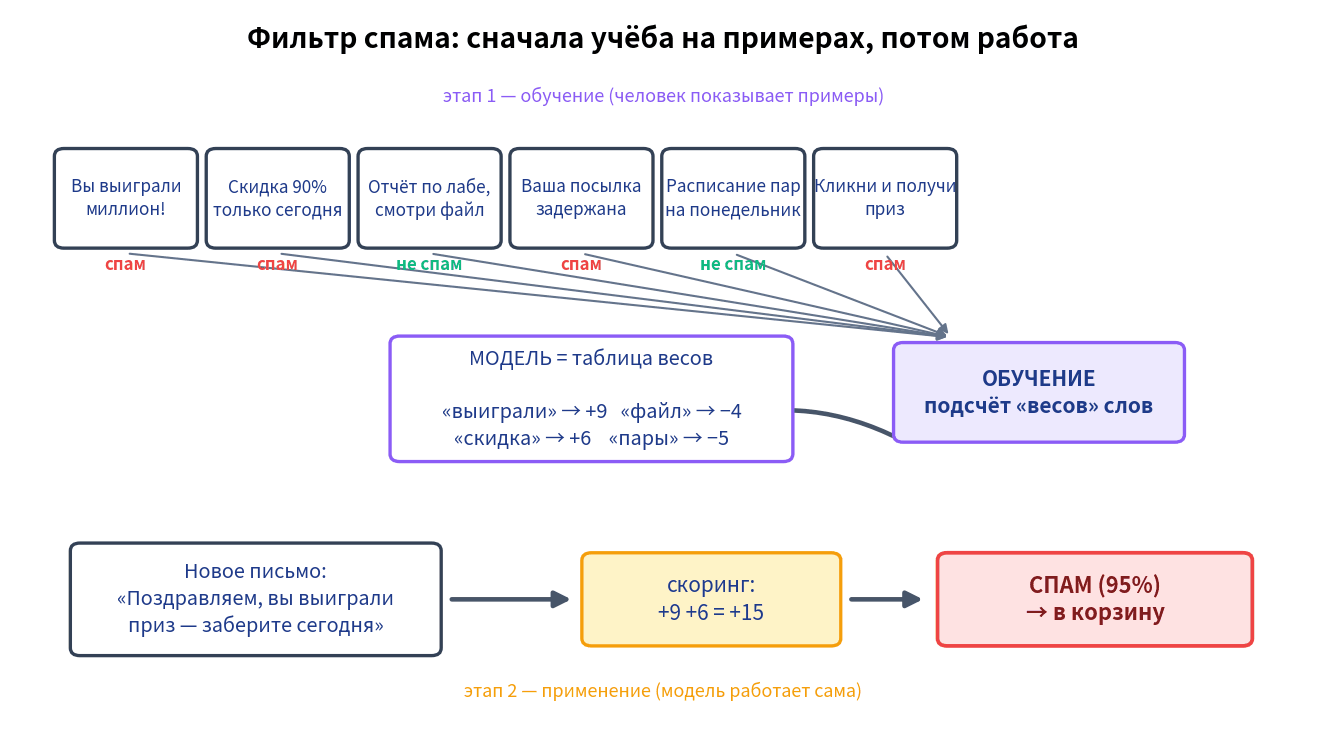

### 3.4. Четыре шага любого обучения (запомните их — это каркас курса)

1. **Данные (数据).** Собрать примеры: письма, фото, показания датчиков.
2. **Признаки и метки (特征与标签).** Превратить каждый пример в числа; для задач «с учителем» — указать правильный ответ.
3. **Обучение (训练).** Алгоритм ищет такие параметры модели, чтобы на примерах ошибаться как можно меньше.
4. **Применение и оценка (预测与评估).** Модель предсказывает ответы для **новых** данных; качество меряем именно на новых, а не на учебных.

**Игра «Станьте моделью» (10 минут, в парах).** Один студент — «модель», другой — «учитель». Учитель показывает 10 «писем» (записки: «скидка 50%», «пересдача в субботу», «выиграл iPhone»…) и к каждому — метку спам/не спам. Модель молча ищет закономерности. Затем учитель показывает 5 новых записок — модель должна предсказать. Сравните предсказания с ответами, обсудите: какие слова оказались «сильными признаками»? Именно так чувствует себя алгоритм.


**Терминология**

В этом уроке разберём основные термины, которые используются в машинном обучении, а также изучим минимальный набор шагов, которые необходимо сделать для решения задачи машинного обучения.



Рассмотрим простой пример. Допустим, по информации о клиенте — его поле, возрасте, среднем доходе, рейтинге кредитной истории и другим характеристикам — мы хотим определить, вернёт ли он кредит.

**Целевая переменная (target)** — величина, которую мы хотим предсказать. В нашем примере это может быть 1, если клиент вернёт кредит, и 0, если не вернёт.

**Признаки (features)** — характеристики, которые мы используем для предсказания. В данном случае это пол, возраст, доход, рейтинг кредитной истории и другие параметры клиента.

**Объекты (objects)** — сущности, для которых мы делаем предсказание. В нашем примере объектами являются клиенты

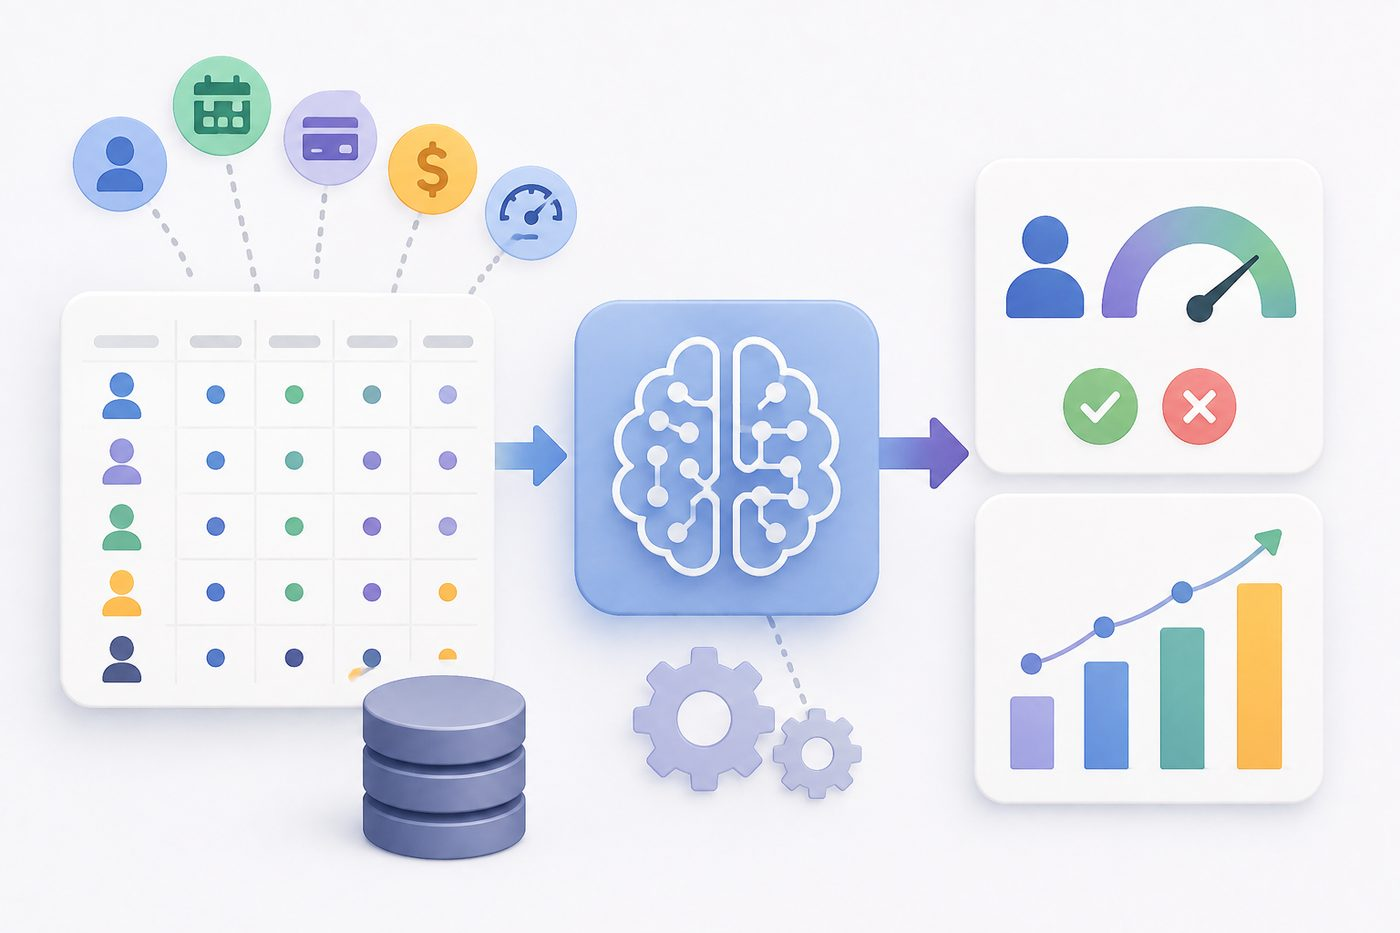

Схема решения стандартных задач машинного обучения
Разберём общую схему решения стандартных задач машинного обучения. В следующих уроках мы подробно остановимся на каждом её этапе, а сейчас сформируем общее представление о том, как устроен этот процесс.


Алгоритмам машинного обучения нужны данные, на которых они могут учиться. В самом общем виде процесс можно разделить на два больших этапа.

**1. Обучение модели**

На этапе обучения модель анализирует большое количество данных, для которых нам известны правильные ответы. Например, мы знаем, какие клиенты вернули кредит, а какие нет, или знаем результаты анализов пациентов и то, здоровы они или больны.

Модель ищет закономерности в этих данных и учится делать предсказания для новых объектов. Набор данных, для которых известны правильные ответы, называется **обучающей выборкой**.

Рассмотрим пример: пусть мы хотим предсказывать стоимость квартиры по её характеристикам.

x=(x1,x2,...,xd)  — признаки одной квартиры;
a(x) — предсказание модели, то есть оценка стоимости квартиры x;
y — правильный ответ, то есть её реальная стоимость.

Задача специалиста по машинному обучению — подобрать и настроить модель
a так, чтобы её предсказания как можно точнее соответствовали правильным ответам. Иными словами, модель должна как можно меньше ошибаться.

**2. Применение модели**

После обучения готовую модель можно применять к новым данным, для которых правильные ответы нам пока неизвестны.

Например, у нас есть информация о нескольких квартирах — площадь, район, количество комнат и другие характеристики, — но их реальная стоимость неизвестна. Мы подаём эти данные на вход обученной модели и получаем предсказание стоимости для каждой квартиры.



Таким образом, на этапе обучения модель учится на данных с известными ответами, а на этапе применения использует полученные закономерности для предсказания ответов на новых данных.

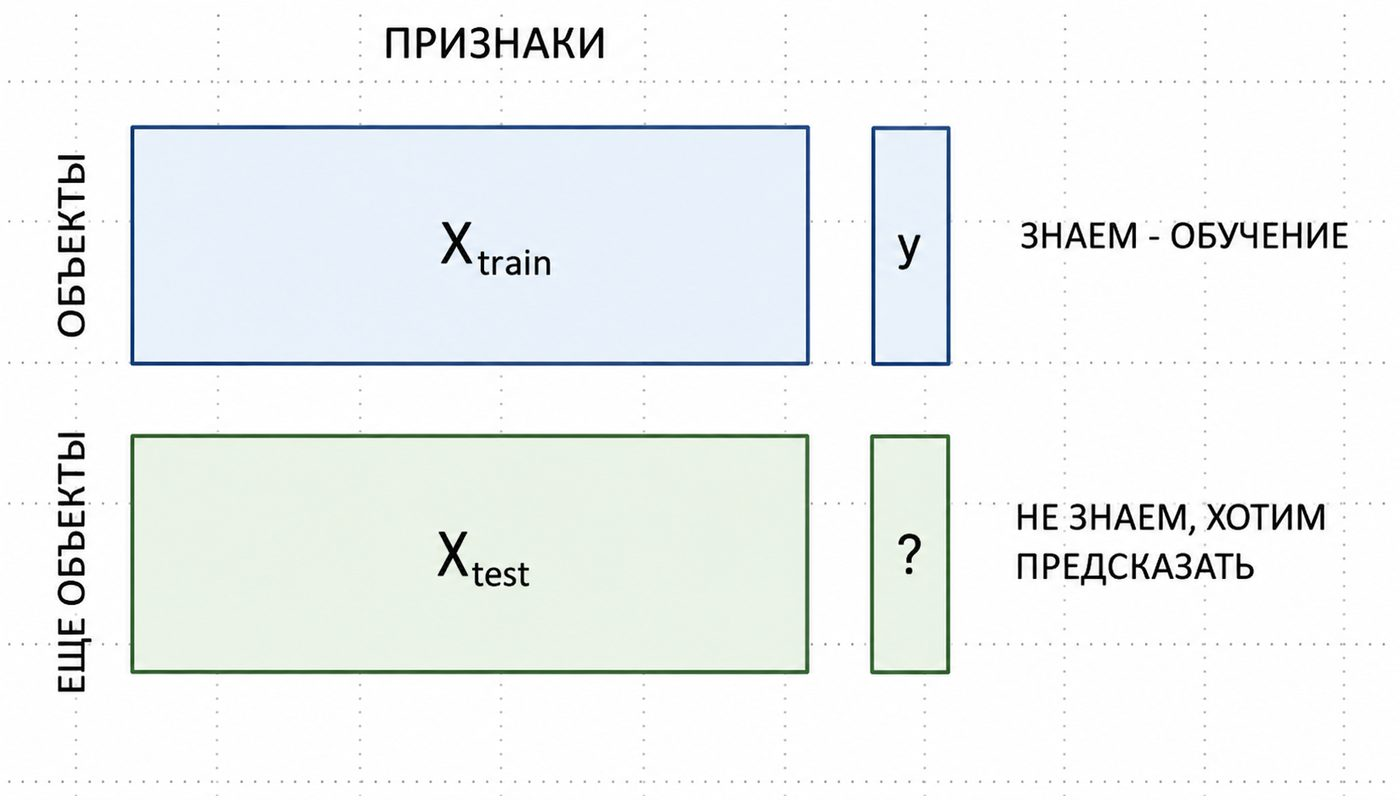

> Добавить блок с цитатой



Таким образом, на **этапе обучения модель учится на данных с известными ответами, а на этапе применения использует полученные закономерности для предсказания ответов на новых данных.**

# Функция потерь

При обучении модели мы хотим минимизировать ошибку предсказаний. Для этого вводится **функция потерь** (*loss function*) — она показывает, насколько предсказания модели отличаются от правильных ответов.

Функция потерь — это способ посчитать ошибку модели: чем меньше значение функции потерь, тем лучше модель справляется с задачей.

> ***Цель обучения*** — подобрать такие параметры модели, при которых функция потерь принимает как можно меньшее значение.

## Пример: задача регрессии

Представим, что модель предсказывает цену квартиры:

- реальная цена: **10 млн ₽**
- предсказание модели: **8 млн ₽**
- ошибка: **2 млн ₽**

Но на практике у нас много объектов, поэтому нужно оценить ошибку сразу на всей обучающей выборке.

Для регрессии часто используют **MSE (mean squared error) — среднюю квадратичную ошибку**:

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Здесь:

- $y_i$ — правильное значение;
- $\hat{y}_i$ — предсказание модели;
- $y_i - \hat{y}_i$ — ошибка предсказания;
- $n$ — количество объектов.

*В процессе обучения модель меняет свои параметры и каждый раз смотрит, уменьшилась ли функция потерь. Так шаг за шагом она ищет параметры, при которых предсказания становятся точнее.*


# Отложенная выборка и кросс-валидация

Одна из важнейших характеристик модели машинного обучения — её **способность к обобщению**, то есть способность хорошо работать не только на тех данных, на которых модель обучалась, но и на новых, ранее не виденных объектах. Поэтому после обучения модели мы должны оценить, как она умеет делать прогнозы на новых для неё данных.

Оценивать качество модели только на обучающей выборке недостаточно: модель может хорошо «запомнить» обучающие данные, но при этом плохо работать на новых. Чтобы проверить, насколько хорошо модель обобщает закономерности, часть исходных данных не используют при обучении, а оставляют для последующей проверки качества.

Такую часть данных называют **отложенной выборкой**.

Существует несколько способов разделить исходный датасет на части и организовать такую проверку. На практике особенно часто используются два подхода:

- **Отложенная выборка** (*hold-out set*) — данные один раз разделяют на обучающую и тестовую части;
- **Кросс-валидация** (*cross-validation*) — данные несколько раз разделяют на обучение и проверку, чтобы получить более устойчивую оценку качества модели.

Оба подхода решают одну и ту же основную задачу: оценить, насколько хорошо модель будет работать на данных, которых она не видела во время обучения.


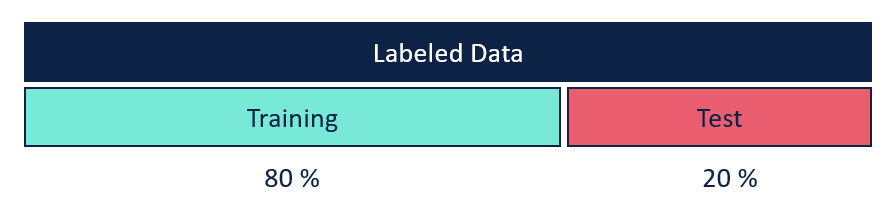

# Минимальная схема машинного обучения

Работу над задачей машинного обучения можно представить как последовательность из нескольких основных шагов.

## 1. Постановка задачи

Сначала нужно понять, **что именно мы хотим предсказать**, и выбрать подходящий тип задачи. Например:
- определить класс объекта — это **классификация**;
- предсказать числовое значение — **регрессия**;
- найти группы похожих объектов — **кластеризация** и т. д.

## 2. Обучение на тренировочных данных

Данные разделяют на части. На **обучающей выборке (train)** модель изучает закономерности: подбирает параметры, которые позволяют делать предсказания как можно точнее.

## 3. Оценка качества на отложенной выборке

После обучения модель проверяют на **отложенной выборке (test)** — данных, которые она не видела при обучении. Здесь оценивают качество с помощью подходящей метрики и проверяют, насколько хорошо модель работает на новых данных.

## 4. Доработка модели

Если качество не устраивает, возвращаются к предыдущим этапам: могут:
- изменить признаки;
- выбрать другую модель;
- настроить гиперпараметры;
- пересмотреть постановку задачи.

Затем снова обучают модель и оценивают её качество.

Таким образом, цикл работы над задачей в машинном обучении — это **итеративный процесс**: поставили задачу → обучили модель → оценили результат → при необходимости доработали и повторили.


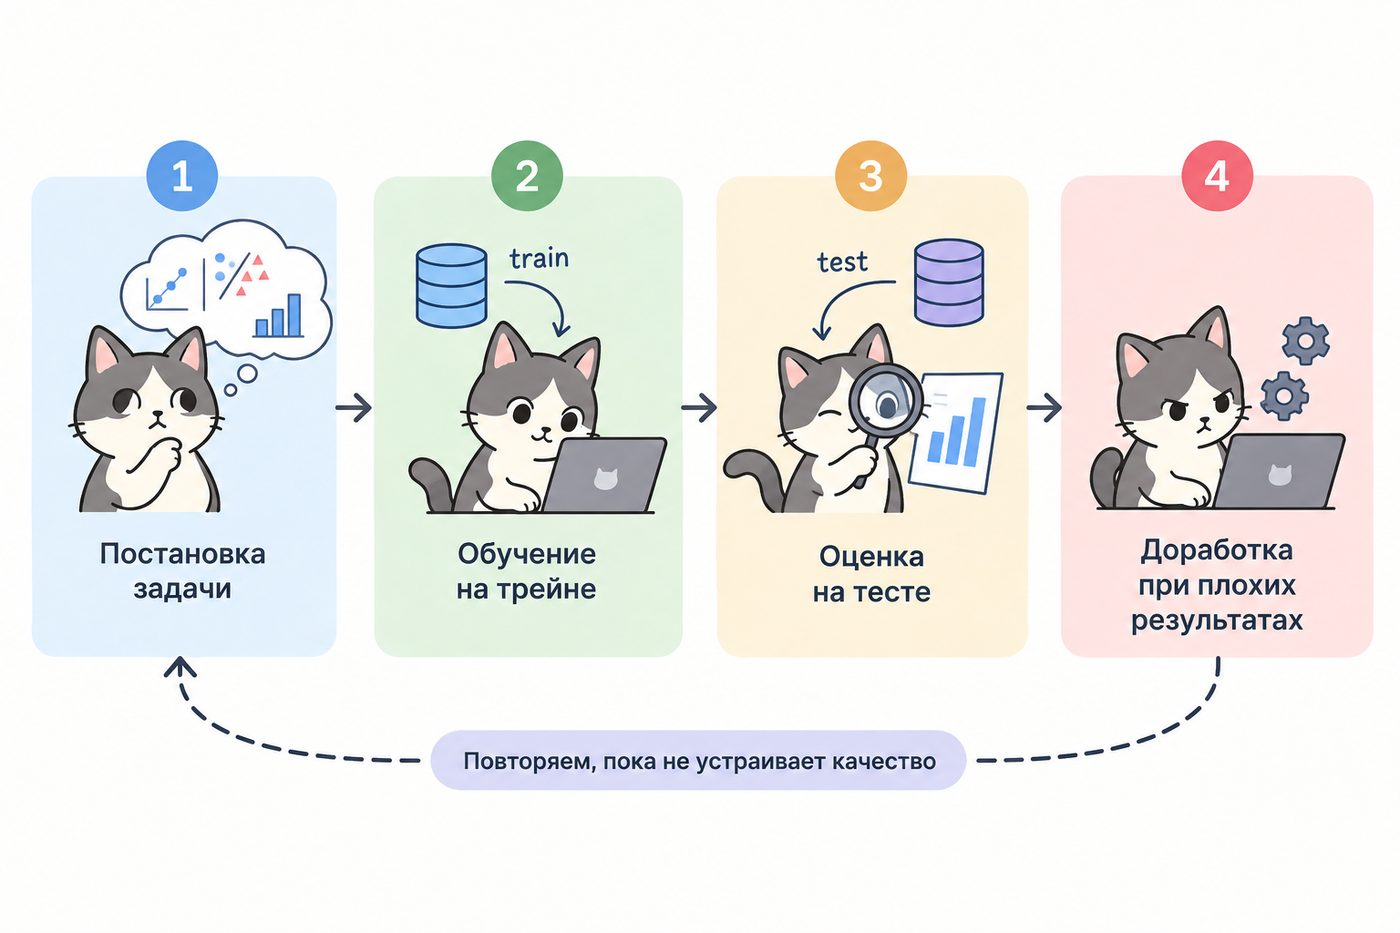

## 4. История ИИ: семь десятилетий за один слайд

ИИ не появился внезапно — у него 70 лет истории с взлётами и двумя «зимами». Знать её полезно: циклы «ажиотаж → разочарование → тихая работа → прорыв» повторяются до сих пор.


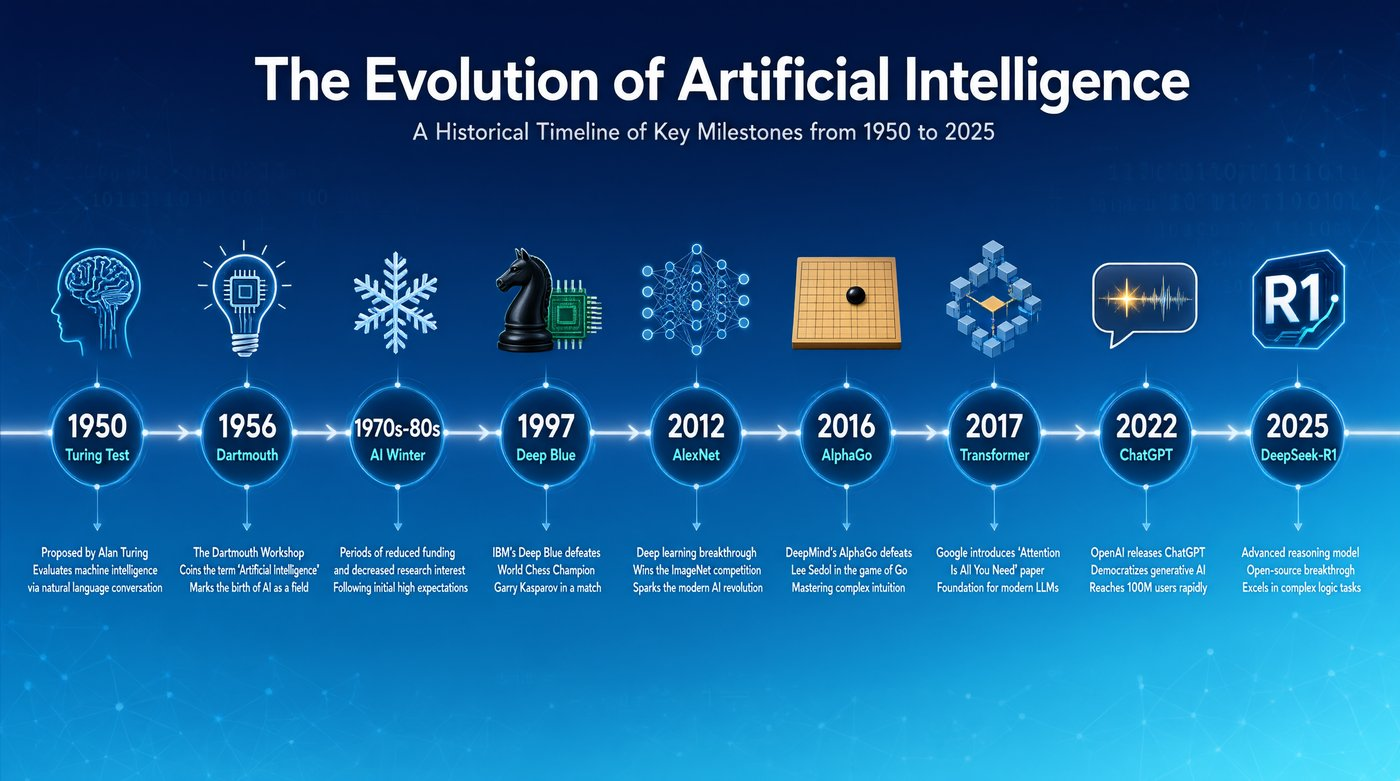

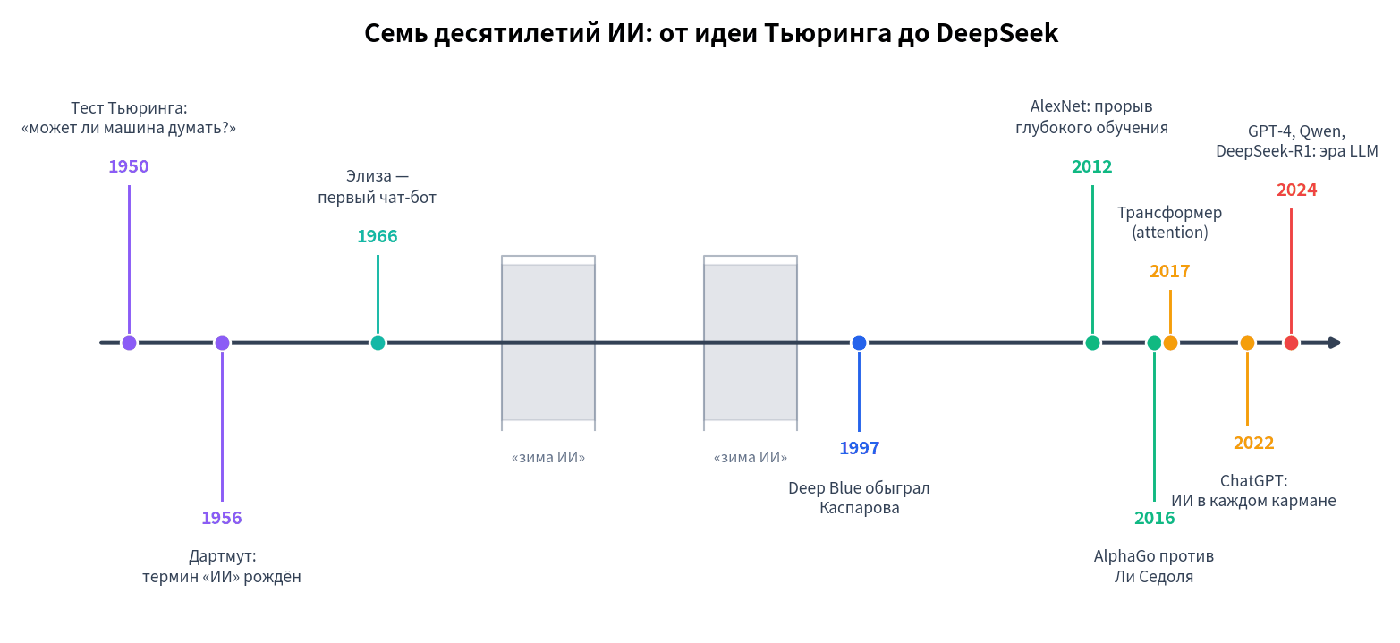

| Год | Событие | Почему это важно |
|---|---|---|
| 1950 | Алан Тьюринг публикует статью «Вычислительные машины и разум», предлагает тест Тьюринга | поставлен вопрос «может ли машина мыслить?» и предложен тест |
| 1956 | Дартмутская конференция | Здесь закрепился термин «искусственный интеллект»; область получила имя и первых энтузиастов |
| 1966 | Элиза (Дж. Вейценбаум) | первый чат-бот: соответствие по ключевым словам; люди уже тогда приписывали ей чувства |
| 1974–1980 | Первая «зима ИИ» | обещания не сбылись, финансирование урезано; урок завышенных ожиданий |
| 1997 | Deep Blue (IBM) обыграл чемпиона мира по шахматам Гарри Каспарова  | машина победила чемпиона мира — но за счет перебора вариантов, не «понимая» игры |
| 2012 |Нейросеть AlexNet побеждает в конкурсе ImageNet по распознаванию изображений | глубокая нейросеть обошла всех на ImageNet на 10 п.п. — начало эпохи глубокого обучения |
| 2016 | AlphaGo против Ли Седоля | победа в го — игре, где «перебор невозможен»;  Модель училась на данных и в играх с самой собой|
| 2017 | Появилась архитектура Transformer; в Китае вышел «План развития ИИ нового поколения» (新一代人工智能发展规划) | архитектура «трансформер» — фундамент всех современных языковых моделей,  ИИ стал национальной стратегией |
| 2022 | ChatGPT | 100 млн пользователей за 2 месяца: ИИ стал повседневным инструментом |
| 2023–2025 | GPT-4, Qwen, Модель DeepSeek-R1 (январь) привлекла внимание всего мира| открытые и коммерческие LLM, рассуждающие модели; ИИ — тема №1 в индустрии, Китайские модели вошли в число самых обсуждаемых|


### 💬 Вопрос для обсуждения

Чем нынешний подъём отличается от прошлых и почему его нельзя считать только «модой»? Ориентир ответа: данные, вычислительная мощность и полезные продукты, которыми люди пользуются каждый день.



| [Ричард Фейнман о возможностях и будущем компьютеров (1985)](https://rutube.ru/video/8c65437e55f31dcc5e899be707e03f34)<br>· ориг.: *Richard Feynman on computers* | Vert Dider (VK/Rutube) | 1 ч 15 мин | Л1 §4: история и взгляд в будущее | X |

### 4.1. Почему бум случился именно сейчас?

Идея нейросетей стара (персептрон — 1958!). Три условия встретились только в 2010-е:

Сошлись **три фактора**:

1. 📊 **Огромное количество данных** (интернет, смартфоны)
2. 💻 **Мощные вычисления** (графические процессоры, GPU)
3. 🧠 **Улучшенные алгоритмы**

Если убрать любой из трёх — прорыва не будет.

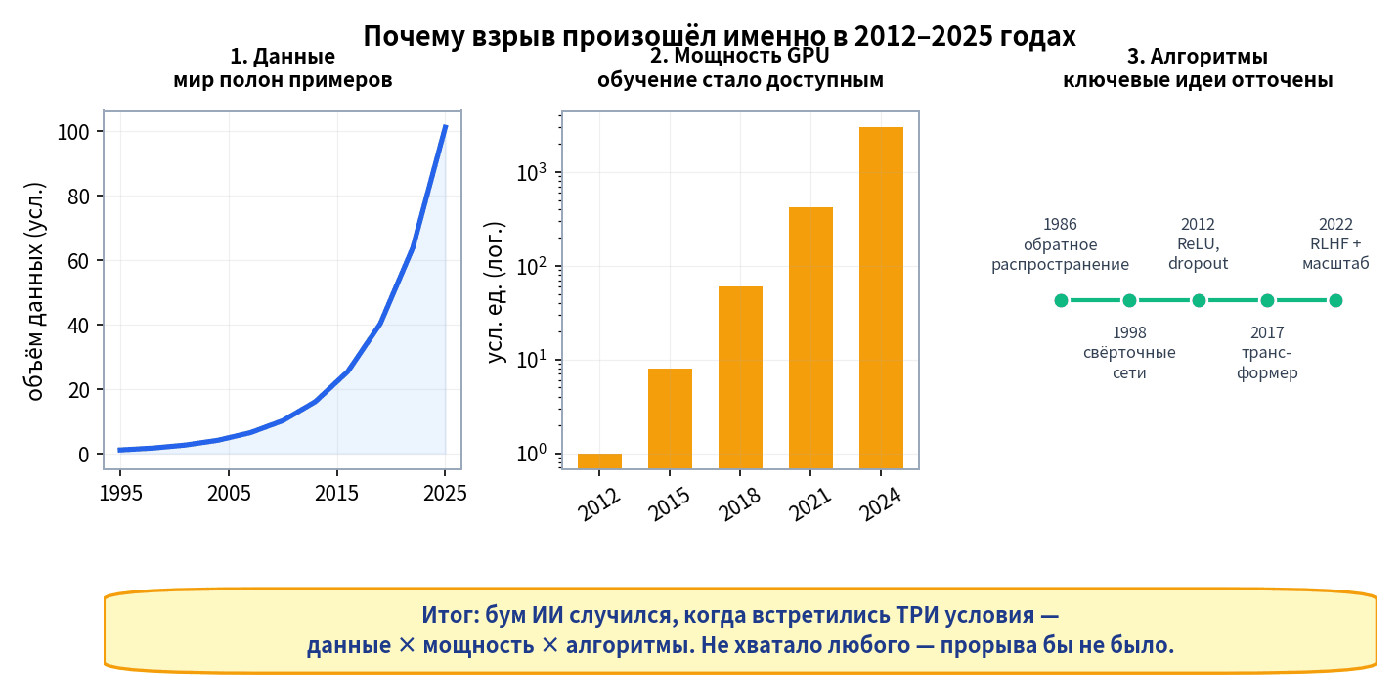
1. **Данные.** Интернет и смартфоны породили миллиарды размеченных примеров: клики, фото с тегами, переводы с выравниванием. Модель, обученная на 100 примерах, игрушка; на 100 миллионах — продукт.
2. **Мощность.** Игровые видеокарты (GPU) оказались идеальны для нейросетей: тысячи ядер одновременно умножают матрицы. С 2012 по 2025 вычислительная мощность обучений выросла на порядки, а облачные сервисы сделали её арендуемой.
3. **Алгоритмы.** ReLU и dropout (2012), Adam (2014), трансформер (2017), масштабирование и RLHF (2020–2022). Каждый кирпич прост; вместе они — здание.

> **Исторический урок для инженера:** прорывы происходят на пересечении. Отличная идея без данных и мощи ждёт 50 лет (персептрон → AlexNet).



### 💬 Мысленный эксперимент: «китайская комната» (Джон Сёрл, 1980)

Проверим интуицию. Человек, не знающий китайского, сидит в комнате с инструкцией: «если пришли иероглифы такого вида — выпишите в ответ такие». Снаружи комната ведёт осмысленную переписку на китайском, и собеседника невозможно распознать. Понимает ли человек внутри китайский? Очевидно нет — он лишь следует правилам. Сёрл утверждал: компьютер делает ровно то же самое.

Спор длится десятилетия, но практический вывод важен уже сегодня: **чат-бот может безупречно отвечать, не «понимая» ни слова.** Доверяйте его ответам как консультации очень начитанного, но не всегда честного помощника: существенное — проверяйте (вернёмся к этому в лекциях 7 и 10).


## 5. Направления ИИ: карта области

Всё, что мы будем изучать в лекциях 3–10, относится к одному из шести направлений:


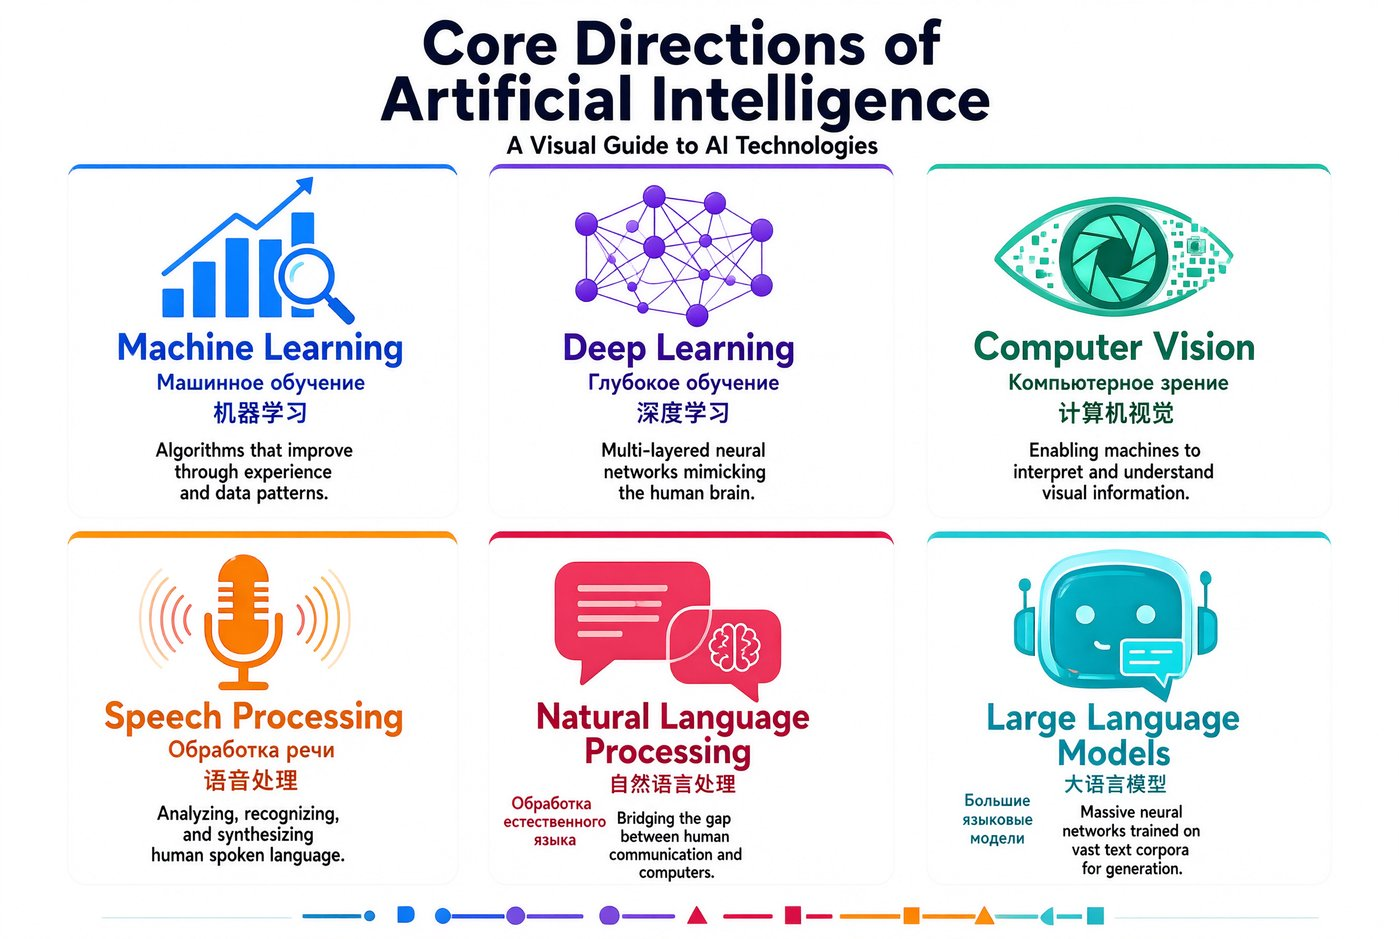

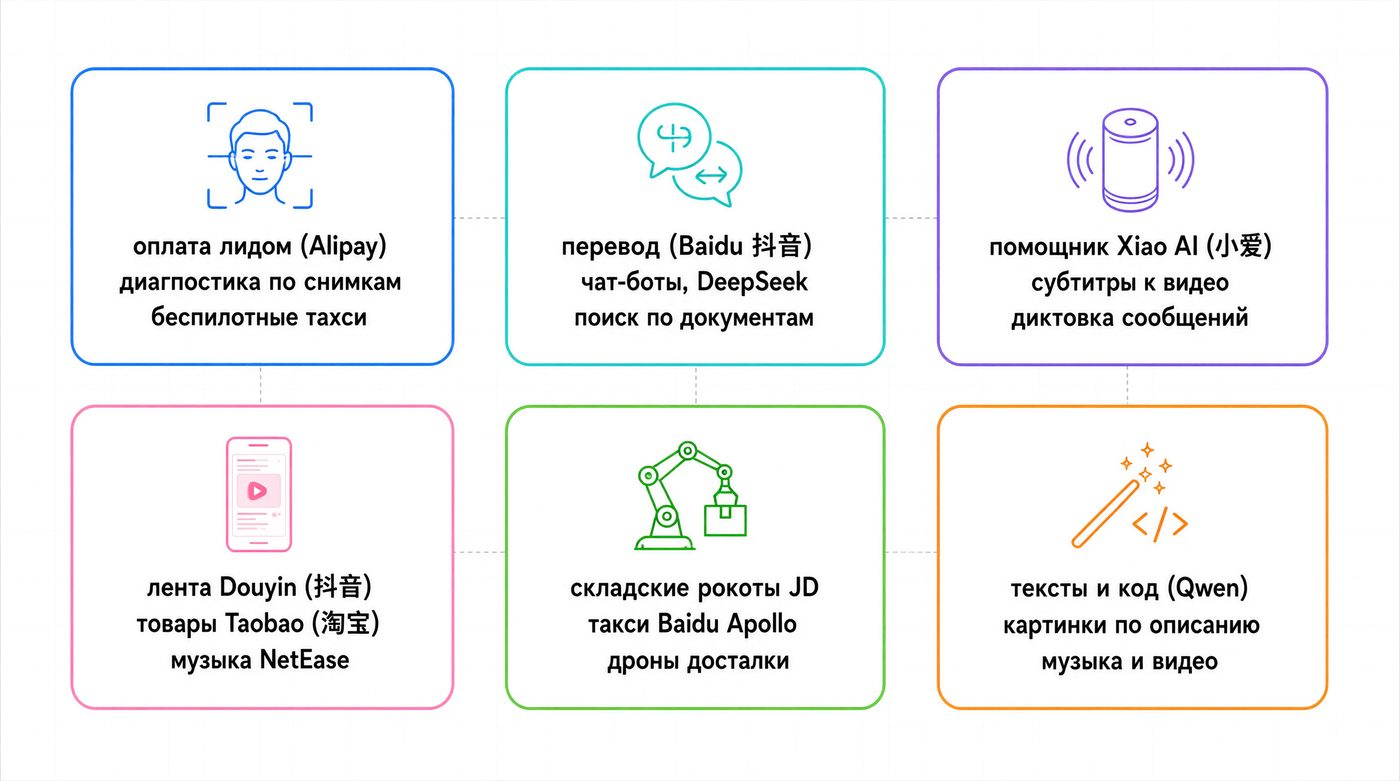
| Направление | Входные данные | Классическая задача | Лекции курса |
|---|---|---|---|
| Компьютерное зрение | пиксели изображения | классификация, детекция, сегментация | 6, 8 |
| Обработка языка (NLP) | текст | перевод, классификация, генерация | 7 |
| Обработка речи | звуковая волна | распознавание (ASR), синтез (TTS) | 8 |
| Рекомендательные системы | история действий | предсказание интереса | 3 (принципы) |
| Робототехника | датчики | управление, навигация | — (упомянем) |
| Генеративный ИИ | текст/шум | создание новых текстов, картинок, кода | 7 |

Заметно, что **в основе почти всего лежит одна и та же пара «представление данных + обучение»** — этому и посвящены центральные лекции курса.



### 🔗 Как направления складываются в цепочку

Направления не конкурируют, а работают вместе. Разберём одно «утро» голосового помощника 小爱同学:

1. **Распознавание речи** превращает звук «какая сегодня погода?» в текст;
2. **Языковая модель** понимает смысл и формулирует ответ;
3. **Синтез речи** озвучивает его;
4. **Рекомендательный блок** решает, что предложить дальше.

Одна бытовая задача — четыре ИИ-системы, каждая со своей математикой. Именно поэтому инженеров, понимающих всю цепочку целиком, ценят выше специалистов одной узкой системы.


---
## 🎬 Видеоматериалы: обзор ИИ и профессии
Обзорные видео к разделам 1–5: что такое ИИ, история, направления.
### 🇷🇺 РУС · русскоязычные видео (2)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [CS50 на русском: Искусственный интеллект (плейлист, 10 лекций)](https://rutube.ru/plst/462333/)<br>· ориг.: *CS50 AI (перевод Vert Dider)* | Rutube · CS50 RU | курс | Л1 целиком: поиск, знание, неопределённость, ML, нейросети, этика  X |
| 2 | [Что полезного сделал ИИ? [Veritasium / Vert Dider]](https://rutube.ru/video/c6c01be661f65b1feabe0f069bf6fb9c/)<br>· ориг.: *What has AI actually done?* | Vert Dider (VK/Rutube) | 23 мин | Л1 §1–2: реальные применения ИИ сегодня  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (4)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [90 минут: ИИ и нейросети за один присест (докладчик из Цинхуа)](https://www.bilibili.com/video/BV1atCRYsE7x?p=1)<br>· ориг.: *90分钟！一口气搞懂人工智能和神经网络* | Bilibili · 漫士 | 1 ч 28 мин | Л1 §2–5: экспресс-обзор всего курса ИИ  ✓ |
| 2 | [Введение в глубокое обучение](https://www.bilibili.com/video/BV1EY6FBwE8P?p=1)<br>· ориг.: *1深度学习介绍* | Bilibili · 李沐 | 13 мин | Л1 §5: куда входит глубокое обучение на карте ИИ  ✓ |
| 3 | [Введение в искусственный интеллект (курс Цинхуа, 36 серий)](https://www.bilibili.com/video/BV1ctQzYUEbz?p=1)<br>· ориг.: *1. 人工智能简介* | Bilibili · 清华36 | 19 мин | Л1 §2–4: определения, история, направления  ✓ |

## 6. Профессии индустрии ИИ

Курс ведёт к конкретным ролям на рынке труда. Обратите внимание: **половина ролей — не про обучение моделей, а про данные и продукты вокруг них**.


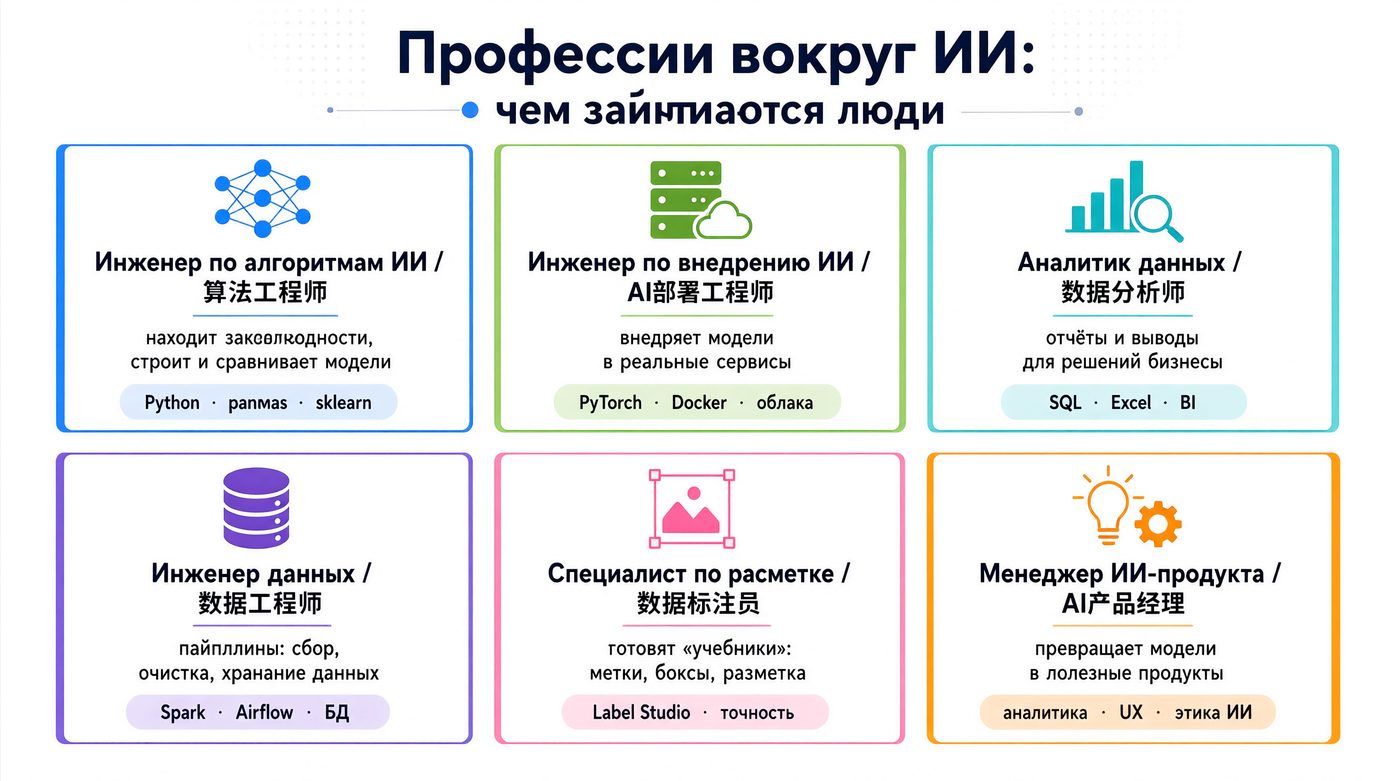

| Профессия | По-китайски | Чем занимается | Что нужно знать |
|---|---|---|---|
| Инженер по алгоритмам ИИ | 算法工程师 | Создаёт и обучает модели,  улучшить модель распознавания документов |Python, основы статистики, PyTorch |
| Аналитик данных | 数据分析师 | Готовит данные, строит отчёты, ищет закономерности, выяснить, почему просели продажи | Pandas, статистика, визуализация |
| Специалист по разметке данных | 数据标注员 | Размечает картинки и тексты для обучения моделей, обвести автомобили на фотографиях по единым правилам  | Внимательность, правила разметки |
| Специалист по применению языковых моделей, промпт-инженер | 提示词工程师 | Настраивает запросы и сценарии для моделей, составить шаблон запроса для службы поддержки | Понимание задачи, умение формулировать |
| Инженер по внедрению ИИ | AI部署工程师 | Встраивает модели в продукты и сервисы, подключить модель к мобильному приложению| Основы программирования, Flask, API |

---


### 🚀 С чего начинать студенту

Для первых шагов не нужна высшая математика: достаточно школьной математики, готовности читать документацию и умения доводить небольшие проекты до результата. Именно такие проекты вы сделаете на практиках этого курса.

> 💡 **Важная мысль:** ИИ чаще автоматизирует отдельные задачи, а не профессии целиком. Выигрывают те, кто умеет использовать ИИ как инструмент в своей области: медицине, торговле, логистике, образовании.

Мини-обзор зарплатных ожиданий и спроса можно поискать самостоятельно (сайты hh.ru, 51job, liepin.com) — цифры быстро устаревают, а вот **структура ролей устойчива годами**.

**❓ Вопрос:** какая роль ближе вам? Что из её инструментов вы уже знаете? (К концу курса у вас будет Python, pandas, scikit-learn, PyTorch — основа для трёх ролей из шести.)



### 🌱 Качества, которые стоит развивать уже сейчас

- **Аккуратность с деталями.** Одна лишняя запятая в данных ломает результат; привычка перепроверять дороже таланта.
- **Умение объяснять просто.** Инженер, который может рассказать заказчику без формул, почему модель рекомендует именно так, стоит вдвое дороже.
- **Языки.** Английская документация появляется раньше переводов, а русско-китайская пара языков — ваше конкурентное преимущество на рынке обеих стран.
- **Дисциплина маленьких проектов.** Портфолио из трёх доведённых до конца работ убеждает работодателя сильнее, чем сертификаты о просмотренных курсах.


## 7. Ограничения: где ИИ проигрывает человеку (сегодня)

Здравый взгляд важнее ажиотажа. Современные системы:


### ⚠️ Ограничения и риски ИИ

Это важно сказать в первой лекции, чтобы у студентов не сложилось образа «всемогущего» ИИ.

1. **Уверенные ошибки.** Языковая модель может выдумать несуществующую статью или цифру и подать их как правду. Любой важный факт нужно проверять по надёжному источнику.
2. **Зависимость от данных.** Если в обучающих данных мало примеров какой-то группы людей, модель хуже работает именно с ней. Например, система подбора резюме, обученная на данных прошлых лет, может повторять прежние перекосы.
3. **Узость.** Шахматная программа не умеет переводить, а система распознавания лиц не умеет предсказывать погоду. Каждая модель решает свою задачу.
4. **Безопасность данных.** Не вводите в публичные модели личные данные, пароли и документы (подробнее в лекции 8).

**Вопрос аудитории:** вы получили ответ от языковой модели. Какие три проверки сделаете, прежде чем использовать его в курсовой работе?

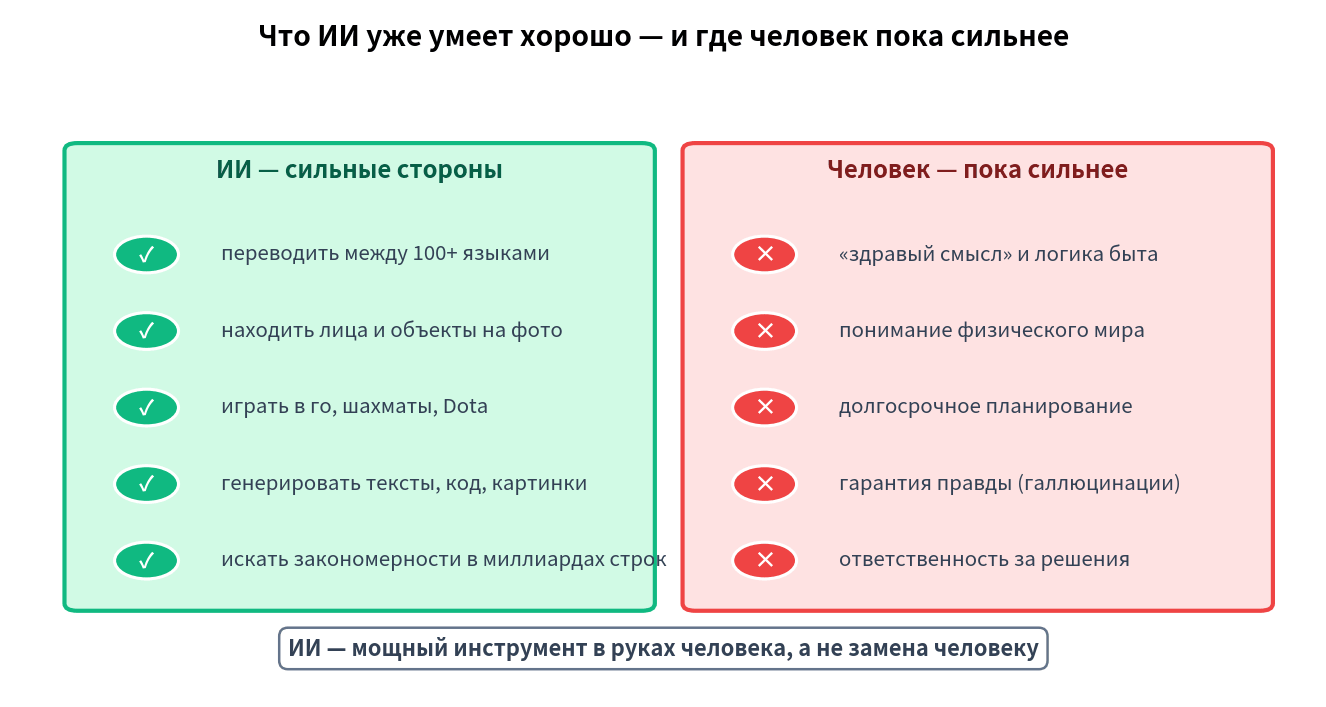

Разберём два самых важных ограничения — они ещё встретятся в лекции 7 и 10.

**Галлюцинации (幻觉).** Языковая модель генерирует *правдоподобный* текст, а не *проверенный*. Она может уверенно «вспомнить» несуществующую статью, придумать формулу с неверной ссылкой. Правило: **ИИ — черновик, человек — редактор.**

**Отсутствие здравого смысла.** Модель, никогда не видевшая физического мира, не «знает», что стакан упадёт со стола. Она знает лишь статистику текстов об стаканах. Отсюда странные ошибки в простых бытовых ситуациях.

Полный разбор этики, предвзятости и правил — в лекции 10.


> 🎯 **Правильная постановка задачи для ИИ:** не «заменить человека», а **«убрать у человека рутину, оставив ему смысл и контроль»**. Так будем думать весь курс: миллион снимков — машине, окончательное решение о диагнозе — врачу.


---
## 🎬 Все видеоматериалы лек\ции 1

### 🇷🇺 РУС · русскоязычные видео (5)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [[RUS Машинный Перевод](https://vkvideo.ru/video-227991006_456239086) | VK · Нга-ML | 4:28 | Л1 §1.1: ИИ вокруг нас — таблица применений ·[добавлено] | X |
| 2 | [Что полезного сделал ИИ? [Veritasium / Vert Dider] (итоговый ракурс)](https://rutube.ru/video/c6c01be661f65b1feabe0f069bf6fb9c)<br>· ориг.: *What has AI actually done?* | Vert Dider (VK/Rutube) | 23 мин | Л10 §6: баланс пользы и рисков — итог курса | X |
| 3 | [Введение в искусственный интеллект. Quo Vadis, AI_](https://vkvideo.ru/video-155161349_456239163) | VK · DLS-1 | 1:15:03 | Обзорная вводная: что такое ИИ и куда развивается область (Л1, раздел 1) ·[добавлено] | X |
| 4 | [Ричард Фейнман о возможностях и будущем компьютеров (1985)](https://rutube.ru/video/8c65437e55f31dcc5e899be707e03f34)<br>· ориг.: *Richard Feynman on computers* | Vert Dider (VK/Rutube) | 1 ч 15 мин | Л1 §4: история и взгляд в будущее | X |
| 5 | [«Введение в искусственный интеллект»](https://stepik.org/course/295326) | Stepik | Stepik / RU | ≈4,5 ч видео, бесплатно ·[добавлено] | ✓ |


### 🇨🇳 中文 · китайскоязычные видео (7)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [100 слов о больших моделях](https://www.bilibili.com/video/BV1DgxCzREbM?p=7)<br>· ориг.: *【入门篇】速览大模型 100 词* | Bilibili (анимакурс) | 11 мин | Л7 §5: словарь терминов LLM | ✓ |
| 2 | [90 минут: ИИ и нейросети за один присест (докладчик из Цинхуа)](https://www.bilibili.com/video/BV1atCRYsE7x?p=1)<br>· ориг.: *90分钟！一口气搞懂人工智能和神经网络* | Bilibili · 漫士 | 1 ч 28 мин | Л1 §2–5: экспресс-обзор всего курса ИИ Цинхуа| ✓ |
| 3 | [Введение в глубокое обучение](https://www.bilibili.com/video/BV1EY6FBwE8P?p=1)<br>· ориг.: *1深度学习介绍* | Bilibili · 李沐 | 13 мин | Л1 §5: куда входит глубокое обучение на карте ИИ | ✓ |
| 4 | [Введение в искусственный интеллект (большой курс Цинхуа, 180 серий)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=3)<br>· ориг.: *1-3 人工智能介绍* | Bilibili · 清华AI | 18 мин | Л1 §2: что изучает ИИ | ✓ |
| 5 | [Введение в искусственный интеллект (курс Цинхуа, 36 серий)](https://www.bilibili.com/video/BV1ctQzYUEbz?p=1)<br>· ориг.: *1. 人工智能简介* | Bilibili · 清华36 | 19 мин | Л1 §2–4: определения, история, направления | ✓ |
| 6 | [Есть ли путь к AGI?](https://www.bilibili.com/video/BV1owrpYKEtP?p=50)<br>· ориг.: *50.是否存在通往AGI的路径* | Bilibili · 吴恩达 (NG, 2025) | 10:35 | Л1 §2.2: узкий ИИ и AGI — важнейшее различие курса ·[добавлено из подборки] ·[добавлено] | ✓ |
| 7 | [Установка PyCharm и Anaconda](https://www.bilibili.com/video/BV1DgxCzREbM?p=8)<br>· ориг.: *【入门篇】pycharm和anaconda的安装* | Bilibili (анимакурс) | 22 мин | Л2 §6 / П1: рабочая среда | ✓ |

### 🇬🇧 EN · англоязычные видео (1)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [吴恩达《AI for Everyone》给所有人的AI课](https://www.bilibili.com/video/BV1LnnE6PEm9) | Bilibili · 吴恩达 AI for Everyone | Bilibili / EN+中字 | 35 эп., 4 ч 21 мин ·[добавлено] | ✓ |

## ❓ Мини-тест

### Проверьте себя

Ответьте устно или письменно:

1. **Чем модель ИИ отличается от обычной программы?**
   <details>
   <summary>Показать ответ</summary>
   Модель ИИ находит правила из данных, обычная программа использует правила, написанные человеком.
   </details>

2. **Какое направление отвечает за разблокировку телефона по лицу?**
   <details>
   <summary>Показать ответ</summary>
   Компьютерное зрение (计算机视觉).
   </details>

3. **В каком году появился термин «ИИ»?**
   <details>
   <summary>Показать ответ</summary>
   1956 год, Дартмутская конференция.
   </details>

4. **Назовите три причины современного бума ИИ.**
   <details>
   <summary>Показать ответ</summary>
   Данные, вычисления (GPU), алгоритмы (глубокое обучение, Transformer).
   </details>

5. **Что такое «узкий ИИ»?**
   <details>
   <summary>Показать ответ</summary>
   ИИ, который хорошо делает одну задачу (например, играет в го или распознаёт лица).
   </details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Приведите три примера использования ИИ из своего последнего дня и укажите направление каждого.**
<details>
<summary>Показать ответ</summary>
Пример: <b>Douyin (抖音)</b> подбирает видео — рекомендации (машинное обучение); <b>оплата лицом в Alipay</b> — компьютерное зрение; <b>голосовой помощник Xiao AI (小爱同学)</b> — обработка речи. Годятся и другие: навигатор 高德地图 (прогноз пробок), Baidu Translate (обработка языка), чат с DeepSeek (генеративный ИИ). Ключевое — назвать направление, а не просто приложение.
</details>

**2. Чем модель ИИ отличается от обычной программы?**
<details>
<summary>Показать ответ</summary>
В обычной программе правила пишет человек: <b>правила + данные → ответы</b>. В модели ИИ правила выводятся из данных автоматически: <b>данные + ответы → правила (модель)</b>. Модель <b>самоулучшается на данных</b> — это ключевое слово определения. Пример: фильтр спама по ручным правилам против весов слов, вычисленных из примеров (§3.3 лекции).
</details>

**3. Назовите не менее четырёх направлений ИИ и приведите по одному китайскому продукту или сервису для каждого.**
<details>
<summary>Показать ответ</summary>
Компьютерное зрение — оплата лицом в Alipay/WeChat Pay; обработка языка (NLP) — Baidu Translate (百度翻译); обработка речи — Xiao AI (小爱同学), Xiaodu (小度); рекомендательные системы — Douyin (抖音), Taobao (淘宝); большие языковые модели — DeepSeek (深度求索), Qwen (通义千问), Kimi. Любые четыре пары «направление → продукт» верны.
</details>

**4. Чем робот отличается от ИИ? Может ли существовать ИИ без робота, а робот без ИИ?**
<details>
<summary>Показать ответ</summary>
<b>Робот — «тело»</b> (моторы, датчики), <b>ИИ — «мозг»</b> (программа, принимающая решения). ИИ без робота существует: навигатор 高德地图, спам-фильтр, языковая модель — ничего физического нет. Робот без ИИ тоже: обычный пылесос или манипулятор по жёсткой программе работают без всякого обучения. В курсе мы изучаем именно «мозг».
</details>

**5. Какие роли в индустрии ИИ доступны начинающим специалистам? Что общего у всех этих ролей?**
<details>
<summary>Показать ответ</summary>
<b>Специалист по разметке данных</b>, <b>аналитик данных</b>, <b>промпт-инженер</b> — вход по внимательности и пониманию задачи, без глубокой математики. Общее у всех ролей: они работают <b>с данными и задачами вокруг модели</b> — а половина индустрии именно такая (§6 лекции).
</details>

**6. Почему оплата лицом — это узкий ИИ, а не AGI?**
<details>
<summary>Показать ответ</summary>
Система решает <b>одну единственную задачу</b>: превращает лицо в вектор из ~128 чисел и сравнивает с образцом. Она не умеет ничего другого: не переводит, не играет в го, не пишет письма. <b>AGI</b> — гипотетическая система, переносящая навыки между областями, как человек; он не создан. Всё, чем мы пользуемся, включая ChatGPT и DeepSeek, — узкий ИИ.
</details>

**7. Назовите три причины бума ИИ 2012–2025. Почему персептрон 1958 года не мог дать прорыва?**
<details>
<summary>Показать ответ</summary>
Три встретившихся условия: <b>данные</b> (интернет и смартфоны породили миллиарды примеров), <b>вычислительная мощность</b> (GPU), <b>алгоритмы</b> (ReLU, Adam, трансформер). Персептрон 1958 года был той же идеей, но без любого из трёх условий — отличная идея ждала данных и мощи 50 лет (перцептрон → AlexNet).
</details>

**8. Ваш друг говорит: «ChatGPT всё знает, зачем учиться?» Напишите три аргумента-контраргумента из этой лекции.**
<details>
<summary>Показать ответ</summary>
<b>1.</b> Галлюцинации: модель выдаёт правдоподобное, а не проверенное — «ИИ — черновик, человек — редактор», кто не учился, не отличит ошибку. <b>2.</b> Узость: у модели нет здравого смысла, она «не знает» физического мира. <b>3.</b> Ответственность: решение всегда за человеком, а пользоваться ИИ как инструментом нужно уметь — выигрывает тот, кто умеет ставить модели задачу. Это и есть повод учиться.
</details>


## 📚 Глоссарий Лекции 1 (词汇表)

Базовые термины модуля 1 — для двуязычной работы и самопроверки.

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Искусственный интеллект | Artificial Intelligence | 人工智能 | Класс систем, выполняющих задачи, требующие человеческого интеллекта. |
| Общий ИИ (AGI) | Artificial General Intelligence | 通用人工智能 | Гипотетический ИИ человеческого уровня во всех задачах; не создан. |
| Узкий (слабый) ИИ | Narrow (weak) AI | 弱人工智能 | ИИ, специализированный на одной задаче; весь используемый сегодня ИИ — узкий. |
| Машинное обучение | Machine Learning | 机器学习 | Подход, при котором система учится на данных, а не по явным правилам. |
| Глубокое обучение | Deep Learning | 深度学习 | Подкласс ML на многослойных нейросетях; основа прорывов 2012+. |
| Тест Тьюринга | Turing Test | 图灵测试 | Критерий интеллекта: человек не может отличить ответы машины от человека. |
| Алгоритм | Algorithm | 算法 | Точное предписание, ведущее от исходных данных к результату. |
| Модель | Model | 模型 | Результат обучения алгоритма на данных; прогнозирует ответы для новых входов. |
| Данные | Data | 数据 | Сырой материал для ML: таблицы, тексты, картинки, звук. |
| Признак | Feature | 特征 | Измеримая характеристика объекта; вход модели. |
| Датасет | Dataset | 数据集 | Набор данных для обучения и тестирования модели. |
| Аннотатор | Annotator | 标注员 | Человек, размечающий данные (метки, рамки) для обучения с учителем. |
| GPU | GPU (Graphics Processing Unit) | 图形处理器 | Графический процессор; массово-параллельные вычисления для глубокого обучения. |
| Data Scientist | Data Scientist | 数据科学家 | Специалист, ведущий проект от данных до модели и выводов. |
| ML Engineer | ML Engineer | 机器学习工程师 | Специалист, ставящий модель в продакшен и поддерживающий её. |
| Product Manager (AI) | AI Product Manager | 人工智能产品经理 | Отвечает за продукт и приоритеты в AI-команде. |
| Галлюцинация (LLM) | Hallucination | 幻觉 | Уверенный, но фактически неверный ответ LLM; причина — статистическая природа. |


## 🎓 Итоги Лекции 1

Лекция открыла курс: ИИ — это класс систем, выполняющих задачи, требующие человеческого интеллекта, а не магия. Ключевое свойство современного ИИ — самообучение на данных; весь используемый сегодня ИИ — узкий, AGI не создан. Матрёшка понятий: ИИ ⊃ ML ⊃ DL.

### 🔑 Главные выводы

1. ИИ — класс систем, выполняющих «интеллектуальные» задачи; ключевое свойство современных систем — **самоулучшение на данных**.
2. Классическое программирование: правила + данные → ответы. Машинное обучение: данные + ответы → правила (модель).
3. Весь используемый сегодня ИИ — **узкий**; AGI не создан.
4. Матрёшка понятий: ИИ ⊃ машинное обучение ⊃ глубокое обучение.
5. Бум 2012–2025 — встреча трёх условий: данные × мощность GPU × алгоритмы.
6. Профессии делятся на «модели» (DS, ML Engineer) и «данные и продукт» (Analyst, Engineer, Annotator, PM).

### 📝 Домашнее задание

1. **Дневник ИИ (3 дня).** Записывайте каждый случай, когда с вами работает ИИ. В конце — таблица из 15+ строк по образцу §1.1.
2. **Сравнение систем.** Выберите две ИИ-системы (например, Douyin-рекомендации и оплату лицом). Для каждой опишите: данные на входе → что предсказывается → чем оценивается качество. Полстраницы на систему.
3. **Правила против обучения.** Придумайте задачу, где ручные правила работают лучше машинного обучения, и объясните почему. (Подсказка: мало данных + нужна объяснимость + правила не меняются.)

### 📅 Следующее занятие

**Лекция 2: Данные — топливо ИИ, математический минимум и среда Python**

**Практика 1: Установка и настройка среды разработки ИИ**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>